# P8 — KGQA Bench: chạy CGAR + PRISM 12 bước trên Colab

Notebook này đi đúng 12 bước của *Sổ tay thực nghiệm CGAR–PRISM*. Mỗi bước = 1 cell markdown (mục tiêu, output kỳ vọng, gate) + 1 cell code.
Mọi cell đều **bỏ qua nếu output đã tồn tại** (xoá thư mục `results/<bước>` để chạy lại). Thứ tự bắt buộc: 00 → 01 → 02 → 03/04 → 05 → 06 → 07..11.

| Bước | Nội dung | GPU | Thời gian ước lượng (A100) |
|---|---|---|---|
| 00 | Thiết lập, test | – | 5 phút |
| 01 | Dữ liệu + trần coverage | – | 10–20 phút |
| 02 | Baseline không học | – | 15 phút |
| 03 | Train CGAR | yes | 1.5–3 giờ |
| 04 | Train PRISM (oracle teacher) | yes | 40 phút |
| 05 | Teacher LLM thật → PRISM | yes | 1.5 giờ |
| 06 | Bảng chính 3 seed + sweep | yes | 6–9 giờ |
| 07 | Calibration & abstention | yes | 20 phút |
| 08 | LLM reader & hallucination | yes | 1–3 giờ / reader |
| 09 | Ablation | yes | 2–3 giờ |
| 10 | Transfer & drift | yes | 1 giờ |
| 11 | Report + checklist claim | – | 1 phút |

## 00 · Thiết lập và smoke test
**Mục tiêu:** xác nhận toàn bộ chuỗi code chạy được trước khi tốn GPU.
**Output kỳ vọng:** `33 passed`, `ALL PASSED` (9 test), thư mục smoke có `results.json`, `report.md`.
**Gate:** mọi test xanh. Nếu fail → lỗi là code, sửa trước.

In [1]:
# ==== 00a. Mount Drive + đường dẫn (SỬA 2 DÒNG ĐẦU NẾU KHÁC) ====
from google.colab import drive; drive.mount('/content/drive')
DRIVE_BASE = '/content/drive/MyDrive/ThS/Research/colab'             # = thư mục colab/ local (chứa graph_rag/, paper/)
GRAPH_RAG  = f'{DRIVE_BASE}/graph_rag'                                       # chứa grl_rag.py, adagraph_cgar_v2.py, prism/, kgqa_bench/
RESULTS    = f'{GRAPH_RAG}/results'
CKPT       = f'{GRAPH_RAG}/ckpt'

import os, sys, json, subprocess, time, shutil, glob
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'; sys.dont_write_bytecode = True   # 2 runtime cùng import từ Drive → không ghi .pyc
for d in glob.glob(f'{GRAPH_RAG}/**/__pycache__', recursive=True): shutil.rmtree(d, ignore_errors=True)
os.makedirs(RESULTS, exist_ok=True); os.makedirs(CKPT, exist_ok=True)
os.chdir(GRAPH_RAG); sys.path.insert(0, GRAPH_RAG)
print('cwd =', os.getcwd())
assert os.path.exists('kgqa_bench/cli.py'), 'kgqa_bench/ chưa được sync lên Drive'

Mounted at /content/drive
cwd = /content/drive/MyDrive/ThS/Research/colab/graph_rag


In [2]:
# ==== 00b. Cài deps + GPU ====
!pip install -q datasets sentence-transformers transformers accelerate scikit-learn networkx tqdm matplotlib
import torch
print('torch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# HF token (chỉ cần cho Llama gated). Thêm secret HF_TOKEN trong Colab → Secrets.
try:
    from google.colab import userdata
    if userdata.get('HF_TOKEN'): os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN'); print('HF_TOKEN set')
except Exception: print('(no HF_TOKEN secret — dùng mirror NousResearch cho Llama)')

torch 2.14.1+cu130 | GPU: NVIDIA A100-SXM4-80GB
(no HF_TOKEN secret — dùng mirror NousResearch cho Llama)


In [3]:
# ==== 00c. Test + smoke run (CPU, ~3 phút) ====
!python test_cgar_v2.py | tail -3
!python tests/test_kgqa_bench.py 2>&1 | grep -E "  ok |  FAIL |PASSED|FAILED"
!python tests/test_hallucination.py 2>&1 | grep -E "  ok |  FAIL |PASSED|FAILED"
!python tests/test_escalation.py 2>&1 | grep -E "  ok |  FAIL |PASSED|FAILED"
!python tests/test_v3_and_analysis.py 2>&1 | grep -E "  ok |  FAIL |PASSED|FAILED"
SMOKE = f'{RESULTS}/b00_smoke'
if not os.path.exists(f'{SMOKE}/results.json'):
    cmd = ('python -m kgqa_bench.cli run --train synthetic:60:0:train --eval synthetic:30:1 '
           '--methods gnnrag_all gnnrag_top5 graphrag_fi cgar prism --embedder hash --device cpu '
           '--cgar-s1-epochs 2 --cgar-s2-steps 10 --prism-distill-epochs 2 --prism-rl-steps 10 '
           f'--prism-d-model 32 --prism-layers 1 --reader dummy --quiet --out {SMOKE}')
    print('exit =', subprocess.call(cmd, shell=True))
print(open(f'{SMOKE}/report.md').read()[:1500])


All tests passed. Safe to train.
  ok test_synthetic_dataset_roundtrip
  ok test_paths_by_k_equals_per_k_extraction
  ok test_prism_samples_share_candidates_with_cgar
  ok test_baselines_and_metrics
  ok test_sbert_topk_and_shared_pool
  ok test_cgar_train_and_run
  ok test_prism_train_and_run
  ok test_llm_reader_attach
  ok test_drift_dataset
  ok test_cli_smoke
ALL PASSED
  ok test_parse_path_text_roundtrip
  ok test_oracle_reader_never_hallucinates
  ok test_claim_labels_absent_intermediate_and_abstention
  ok test_judge_hook_refines_uncertain
  ok test_compare_and_review_and_cli
  ok test_grounded_prompt_variant
ALL PASSED
  ok test_curve_endpoints_and_oracle
  ok test_llm_columns_and_cli
ALL PASSED
  ok test_proof_info_and_directed_sequence
  ok test_cgar_v3_train_run_and_ckpt_compat
  ok test_loss_options_change_targets
  ok test_analysis_cli
  ok test_cli_v3_flags_smoke
ALL PASSED
# KGQA bench report

Config: `{"cmd": "run", "train": "synthetic:60:0:train", "eval": ["synthetic

In [3]:
# ==== 00d. Helper dùng chung cho các bước sau ====
import pandas as pd

def run_bench(out, train=None, evals=(), methods=(), extra='', force=False):
    """Gọi CLI; bỏ qua nếu results.json đã có (force=True để chạy lại)."""
    if os.path.exists(f'{out}/results.json') and not force:
        R = load_results(out)
        have = {m for by_m in R['summaries'].values() for m in by_m}
        missing = [m for m in methods if not any(h == m or h.startswith(m + '_k') for h in have)]
        stored_evals = list(R.get('config', {}).get('eval', []))
        spec_changed = bool(stored_evals) and sorted(stored_evals) != sorted(evals)   # ví dụ CWQ heuristic -> CWQ GNN
        if not missing and not spec_changed:
            print(f'[skip] {out} đã có results.json'); return R
        why = f'thiếu {missing}' if missing else f'spec eval đổi (cũ: {[e.split(":")[0] + ":" + e.split(":")[1].split("/")[-1] for e in stored_evals]})'
        print(f'[rerun] {out} {why} → chạy lại (bản cũ đổi tên *_old)')
        old = f'{out}_old'; i = 1
        while os.path.exists(old): i += 1; old = f'{out}_old{i}'
        os.rename(out, old)
    cmd = f'python -m kgqa_bench.cli run --device {DEVICE} --out {out} '
    if train: cmd += f'--train {train} '
    cmd += '--eval ' + ' '.join(evals) + ' --methods ' + ' '.join(methods) + ' ' + extra
    print('$', cmd); t0 = time.time()
    rc = subprocess.call(cmd, shell=True)
    print(f'exit={rc}  {(time.time()-t0)/60:.1f} min')
    return load_results(out)

def load_results(out):
    with open(f'{out}/results.json') as f: return json.load(f)

COLS = ['n','f1','cov','prec','hit_ctx','cost','n_tokens','latency_ms','ece','aurc','sel_acc@80','las_hit1','llm_hit','llm_f1','llm_unsupported_rate']
def show(R, cols=COLS):
    for ds, by_m in R['summaries'].items():
        df = pd.DataFrame(by_m).T
        df = df[[c for c in cols if c in df.columns]]
        print(f'\n=== {ds} ==='); display(df.round(3))

def show_cmp(R):
    rows = []
    for ds, pairs in R['comparisons'].items():
        for k, c in pairs.items():
            if not c or not c.get('n'): continue
            b = c['bootstrap']
            rows.append(dict(dataset=ds, pair=k, n=c['n'], delta=round(b['delta']*100,2),
                             ci=f"[{b['ci_low']*100:+.2f},{b['ci_high']*100:+.2f}]", p=round(b['p_value'],4),
                             mcnemar_p=round(c.get('mcnemar',{}).get('p_value', float('nan')),4), sig=c['significant_0.05']))
    display(pd.DataFrame(rows))

def gate(cond, msg):
    print(('PASS  ' if cond else 'FAIL  ') + msg)

# Pool ứng viên WebQSP: USE_GNN = 'auto' dùng features GNN-RAG (ReaRev) nếu P8b cell 01 đã tạo
# ckpt/gnn_features_*.pkl; True = bắt buộc GNN; False = heuristic (RoG HF) cho vòng ablation.
USE_GNN = 'auto'
_tr, _te = f'{CKPT}/gnn_features_train.pkl', f'{CKPT}/gnn_features_webqsp_test.pkl'
if USE_GNN == 'auto': USE_GNN = os.path.exists(_tr) and os.path.exists(_te)
if USE_GNN:
    assert os.path.exists(_tr) and os.path.exists(_te), 'thiếu ckpt/gnn_features_*.pkl → chạy P8b cell 01 trước'
    WEBQSP_TR = f'gnnrag:{_tr}:webqsp:train'
    WEBQSP_TE = f'gnnrag:{_te}:webqsp:test'
else:
    WEBQSP_TR = 'rog:rmanluo/RoG-webqsp:train'
    WEBQSP_TE = 'rog:rmanluo/RoG-webqsp:test'
# CWQ (C2): dùng features ReaRev nếu P8b đã dựng ckpt/gnn_features_cwq_test.pkl, ngược lại heuristic (các dòng CWQ chỉ để minh hoạ pool)
_cwq = f'{CKPT}/gnn_features_cwq_test.pkl'
CWQ_TE = f'gnnrag:{_cwq}:cwq:test' if os.path.exists(_cwq) else 'rog:rmanluo/RoG-cwq:test'
# PRISM: 'auto' = quyết định ở cell 04 bằng gate (LAS trên mức chance, cost không hằng); False = nhánh CGAR-only
# (bỏ 05, phần PRISM của 06–10); True = bắt buộc chạy PRISM đầy đủ.
RUN_PRISM = False   # vòng 11/2026: CGAR-only; PRISM oracle đã qua gate (las 0.661 vs chance 0.451) → chạy vòng riêng sau nếu cần ('auto'/True)
# Budget đường của CGAR: 5 trên pool GNN (cost ≈ 5.1 như Seminar 1; pool chỉ ~5.6 ứng viên nên 10 ≈ "all"),
# 10 trên pool heuristic (như lần 11/2026). Dùng thống nhất ở cell 03, 06, 09, 10.
CGAR_BUDGET = 5 if WEBQSP_TR.startswith('gnnrag:') else 10
# ---- Cải tiến 11/2026 (xem paper/CGAR_PRISM_models_flow_results_2026-11.md §12) ----
CGAR_S2_STEPS = 0            # B4: S1 supervised là phương pháp chính (RL +0.19 pp, p=0.033 → vào ablation 09)
# B1 learned stop + B2 nhãn proof + B3 confidence theo hit. Cell 03 train cả bản gốc lẫn v3 và CHỌN TRÊN DEV;
# bản được chọn dùng cho 06/08/10 qua CGAR_FLAGS. Đặt CGAR_VARIANT = None để bỏ qua v3.
CGAR_VARIANT = '--cgar-learned-stop --cgar-rel-label proof --cgar-conf-target hit'
CGAR_FLAGS = ''              # cell 03 đặt lại ('' = gốc, CGAR_VARIANT = v3)
READER_PROMPTS = ['chat', 'grounded']   # D1: ma trận prompt gốc × grounded (chỉ trả lời từ paths, cho phép 'unknown')
EMB_MODEL = 'all-MiniLM-L6-v2'   # = embedder mặc định của CLI (--embedder sbert); cell 07/10 phải dùng cùng model
SPEC_TAG = 'gnn' if WEBQSP_TR.startswith('gnnrag:') else 'heur'
RESULTS  = f'{GRAPH_RAG}/results' + ('_gnn' if SPEC_TAG == 'gnn' else '')   # tách kết quả theo loại pool ứng viên
os.makedirs(RESULTS, exist_ok=True)
print('helpers ready | pool =', SPEC_TAG, '| RESULTS =', RESULTS, '| CGAR_BUDGET =', CGAR_BUDGET, '| CWQ =', 'gnn' if CWQ_TE.startswith('gnnrag:') else 'heur'); print('WEBQSP_TR =', WEBQSP_TR)

helpers ready | pool = gnn | RESULTS = /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn | CGAR_BUDGET = 5 | CWQ = gnn
WEBQSP_TR = gnnrag:/content/drive/MyDrive/ThS/Research/colab/graph_rag/ckpt/gnn_features_train.pkl:webqsp:train


In [5]:
# ==== 00e. (Tuỳ chọn) Dùng lại kết quả P8b đã chạy trên cùng pool GNN ====
# P8b cell 02/03 chạy đúng lệnh CLI như P8 cell 02/03 (pool 20, --cgar-max-paths 5) → copy sang để run_bench bỏ qua.
# Chỉ copy khi results.json đã có (CLI ghi file này ở cuối) → an toàn kể cả khi P8b đang train dở.
if SPEC_TAG == 'gnn':
    for g, b in [('g02_baselines', 'b02_baselines'), ('g03_cgar', 'b03_cgar')]:
        src, dst = f'{GRAPH_RAG}/results/{g}', f'{RESULTS}/{b}'
        if os.path.exists(dst): print(f'[có sẵn] {dst}')
        elif os.path.exists(f'{src}/results.json'): shutil.copytree(src, dst); print(f'[copy] {g} → {dst}')
        else: print(f'[chưa xong] P8b {g} chưa có results.json → cell tương ứng của P8 sẽ tự chạy (hoặc chạy lại cell này sau)')
    # cache CWQ heuristic (3531 câu, ~10 phút) dùng chung được
    os.makedirs(f'{RESULTS}/data_cache', exist_ok=True)
    for f in glob.glob(f'{GRAPH_RAG}/results/data_cache/cwq_*.pkl'):
        d = f'{RESULTS}/data_cache/{os.path.basename(f)}'
        if not os.path.exists(d): shutil.copy(f, d); print('[copy cache]', os.path.basename(f))
else:
    print('[skip] pool heuristic: P8b không có gì để dùng lại')

[có sẵn] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b02_baselines
[có sẵn] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b03_cgar


## 01 · Dữ liệu và trần coverage
**Mục tiêu:** nạp WebQSP/CWQ về dạng chung; biết `answer_in_subgraph_rate` = recall tối đa của *mọi* selector.
**Output kỳ vọng:** WebQSP test 1628 câu, CWQ 3531. Trần subgraph RoG: 0.956 / 0.807 (đo 11/2026), mean_hops 1.3 / 1.43, ~4.3k triple mỗi câu. Với features GNN-RAG (P8b): trần ≈0.73.
**Gate:** trần RoG ≥ 0.9 hoặc trần GNN trong [0.65, 0.85] tuỳ nguồn pool. Khoảng cách giữa trần subgraph (0.96) và hit của pool 20 ứng viên (0.33 ở bước 02) chính là phần scorer heuristic làm mất.

In [6]:
from kgqa_bench.data import load_spec
DATA_CACHE = f'{RESULTS}/data_cache'
stats = {}
for spec in (WEBQSP_TR, WEBQSP_TE, CWQ_TE):
    ds = load_spec(spec, cache_dir=DATA_CACHE)
    stats[ds.key] = ds.stats(); print(ds.key, stats[ds.key])
display(pd.DataFrame(stats).T.round(3))
ceil = stats['webqsp:test']['answer_in_subgraph_rate']; src = str(stats['webqsp:test']['source'])
if src.startswith('gnnrag_pkl'):
    gate(0.80 <= ceil <= 0.95, f'trần subgraph WebQSP(GNN features) = {ceil:.3f} trong [0.80, 0.95] (11/2026: 0.887)')
    import numpy as np
    te_ = load_spec(WEBQSP_TE, cache_dir=DATA_CACHE)
    ph = float(np.mean([any(a in set(q.top_candidates) for a in q.answers) for q in te_ if q.answers]))
    gate(0.65 <= ph <= 0.85, f'đáp án trong pool ứng viên ReaRev (test) = {ph:.3f} (Seminar 1 ≈ 0.73; heuristic ≈ 0.33)')
else:
    gate(ceil >= 0.9, f'trần coverage WebQSP(subgraph RoG) = {ceil:.3f} ≥ 0.9 (lần 11/2026: 0.956; CWQ 0.807)')
    print('Lưu ý: đây là trần của SUBGRAPH. Pool 20 ứng viên heuristic chỉ chứa đáp án ở ~33% câu (hit_ctx gnnrag_all ở bước 02) → scorer là nút thắt, không phải dữ liệu.')
json.dump(stats, open(f'{RESULTS}/b01_dataset_stats.json','w'), indent=2)

webqsp:train {'dataset': 'webqsp:train', 'n': 2848, 'source': 'gnnrag_pkl:gnn_features_train.pkl', 'answer_in_subgraph_rate': 0.8862359550561798, 'mean_hops': 1.3026941362916007, 'mean_triples': 4221.4195926966295, 'mean_n_gold': 11.180126404494382, 'mean_n_candidates': 5.072682584269663}
webqsp:test {'dataset': 'webqsp:test', 'n': 1639, 'source': 'gnnrag_pkl:gnn_features_webqsp_test.pkl', 'answer_in_subgraph_rate': 0.8871262965222697, 'mean_hops': 1.3060522696011003, 'mean_triples': 4306.003050640635, 'mean_n_gold': 10.12934716290421, 'mean_n_candidates': 5.599755948749237}
cwq:test {'dataset': 'cwq:test', 'n': 3531, 'source': 'gnnrag_pkl:gnn_features_cwq_test.pkl', 'answer_in_subgraph_rate': 0.7153780798640612, 'mean_hops': 1.4560570071258907, 'mean_triples': 4272.564995751912, 'mean_n_gold': 1.890682526196545, 'mean_n_candidates': 5.234211271594449}


,dataset,n,source,answer_in_subgraph_rate,mean_hops,mean_triples,mean_n_gold,mean_n_candidates
webqsp:train,webqsp:train,2848,gnnrag_pkl:gnn_features_train.pkl,0.886236,1.302694,4221.419593,11.180126,5.072683
webqsp:test,webqsp:test,1639,gnnrag_pkl:gnn_features_webqsp_test.pkl,0.887126,1.306052,4306.003051,10.129347,5.599756
cwq:test,cwq:test,3531,gnnrag_pkl:gnn_features_cwq_test.pkl,0.715378,1.456057,4272.564996,1.890683,5.234211


PASS  trần subgraph WebQSP(GNN features) = 0.887 trong [0.80, 0.95] (11/2026: 0.887)
PASS  đáp án trong pool ứng viên ReaRev (test) = 0.826 (Seminar 1 ≈ 0.73; heuristic ≈ 0.33)


## 02 · Baseline không học
**Mục tiêu:** đường cơ sở cost–quality và các bất đẳng thức bắt buộc: Rec(all) > Rec(top10) > Rec(top5) > Rec(top3); Rec(random_k5) < Rec(top5).
**Output kỳ vọng:** cost top-K đúng bằng K; GraphRAG-FI nằm giữa top5 và top10. Mọi baseline dùng chung pool 20 ứng viên với CGAR (`--baseline-candidates 20`, mặc định). `sbert_topK` = xếp đường theo cosine(câu hỏi, đường) bằng chính embedder của CGAR, không học: đây là mốc CGAR phải vượt rõ.
**Gate:** random_k5 thua top5 với CI không chồng. Nếu random ≈ top-K → scorer không có tín hiệu: thêm `--score-sim 0.5` hoặc dùng GNN-RAG features thật.

In [4]:
B02 = f'{RESULTS}/b02_baselines'
R02 = run_bench(B02, evals=[WEBQSP_TE, CWQ_TE],
                methods=['gnnrag_all','gnnrag_top10','gnnrag_top5','gnnrag_top3','sbert_top10','sbert_top5','graphrag_fi','random_k5'],
                extra='--compare-ref gnnrag_top5 --quiet')
show(R02)
s = R02['summaries']['webqsp:test']
gate(s['gnnrag_all']['cov'] > s['gnnrag_top10']['cov'] > s['gnnrag_top5']['cov'] > s['gnnrag_top3']['cov'], 'Rec giảm đơn điệu theo K')
gate(s['random_k5']['hit_ctx_ci_high'] < s['gnnrag_top5']['hit_ctx_ci_low'], 'random_k5 < top5 (CI không chồng)')
TOPK_AT_COST5 = s['gnnrag_top5']['f1']; print('mốc F1 top-5 (cost 5) =', round(TOPK_AT_COST5*100, 2))
SBERT_AT_COST10 = s['sbert_top10']['f1']; SBERT_AT_COST5 = s['sbert_top5']['f1']
print('mốc F1 sbert_top10 (cost 10) = %.2f | sbert_top5 (cost 5) = %.2f' % (SBERT_AT_COST10*100, SBERT_AT_COST5*100))
gate(s['sbert_top5']['hit_ctx'] > s['gnnrag_top5']['hit_ctx'] or s['random_k5']['hit_ctx_ci_high'] < s['gnnrag_top5']['hit_ctx_ci_low'], 'ít nhất một ranking (GNN hoặc SBERT) có tín hiệu so với random')

[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b02_baselines đã có results.json

=== webqsp:test ===


,n,f1,cov,prec,hit_ctx,cost,n_tokens,latency_ms,ece,aurc,sel_acc@80
gnnrag_all,1628.0,0.411,0.720,0.339,0.832,8.369,109.553,17.898,0.436,0.196,0.820
gnnrag_top10,1628.0,0.396,0.666,0.338,0.807,5.124,62.219,17.940,0.411,0.203,0.810
gnnrag_top5,1628.0,0.377,0.605,0.335,0.782,3.448,40.382,17.980,0.387,0.211,0.792
gnnrag_top3,1628.0,0.351,0.536,0.326,0.750,2.451,27.820,17.918,0.357,0.227,0.761
sbert_top10,1628.0,0.401,0.679,0.344,0.816,5.124,62.232,33.489,0.198,0.143,0.847
sbert_top5,1628.0,0.385,0.619,0.344,0.790,3.448,40.461,18.393,0.174,0.163,0.822
graphrag_fi_k8,1628.0,0.382,0.623,0.336,0.797,4.310,52.143,18.200,0.401,0.206,0.801
random_k5,1628.0,0.377,0.607,0.338,0.781,3.448,40.830,16.982,NaN,NaN,NaN



=== cwq:test ===


,n,f1,cov,prec,hit_ctx,cost,n_tokens,latency_ms,ece,aurc,sel_acc@80
gnnrag_all,3531.0,0.216,0.621,0.146,0.658,11.844,192.292,19.202,0.298,0.288,0.656
gnnrag_top10,3531.0,0.218,0.578,0.149,0.621,5.729,83.771,19.100,0.264,0.295,0.644
gnnrag_top5,3531.0,0.218,0.529,0.151,0.580,3.779,53.809,19.090,0.232,0.306,0.621
gnnrag_top3,3531.0,0.215,0.477,0.152,0.542,2.628,36.883,19.022,0.212,0.319,0.593
sbert_top10,3531.0,0.219,0.593,0.149,0.635,5.729,84.903,34.106,0.050,0.322,0.659
sbert_top5,3531.0,0.222,0.551,0.154,0.600,3.779,54.555,19.382,0.049,0.353,0.624
graphrag_fi_k8,3531.0,0.217,0.557,0.150,0.606,4.914,71.439,19.142,0.251,0.298,0.636
random_k5,3531.0,0.213,0.530,0.148,0.580,3.779,54.854,19.235,NaN,NaN,NaN


PASS  Rec giảm đơn điệu theo K
FAIL  random_k5 < top5 (CI không chồng)
mốc F1 top-5 (cost 5) = 37.67
mốc F1 sbert_top10 (cost 10) = 40.13 | sbert_top5 (cost 5) = 38.47
PASS  ít nhất một ranking (GNN hoặc SBERT) có tín hiệu so với random


## 03 · Huấn luyện CGAR
**Mục tiêu:** controller CGAR chọn checkpoint trên **dev tách từ train** (không phải test). Đo S2 (RL) có học không.
**Output kỳ vọng:** `rel_loss` giảm từ ≈0.69 (= log 2) xuống <0.5; `eval_f1` tăng rồi phẳng; `advantage_nonzero_frac` gần 0 (Seminar 1). WebQSP test F1 ≈40 / Rec ≈69 / cost ≈5 với GNN features thật, thấp hơn vài điểm với scorer heuristic.
**Budget:** `--cgar-max-paths` = `CGAR_BUDGET` (5 trên pool GNN như Seminar 1, 10 trên heuristic), dùng thống nhất ở 03/06/08/09/10. **Gate:** eval_f1 dev ≥ F1 top-K cùng cost; rel_loss < 0.6; F1 CGAR ≥ sbert_topK cùng cost + 1 pp. Mục *Adaptivity* trong report.md phải cho thấy cost/chosen_k thay đổi theo câu; nếu "constant" → bật `--cgar-rel-threshold`.

In [5]:
B03 = f'{RESULTS}/b03_cgar'
# bản gốc v2.1 (S1; S2 chỉ khi CGAR_S2_STEPS>0). Thư mục cũ có S2=300 vẫn được dùng lại (ckpt S1 giống nhau).
R03 = run_bench(B03, train=WEBQSP_TR, evals=[WEBQSP_TE, CWQ_TE], methods=['cgar'],
                extra=f'--dev-split 0.1 --cgar-max-paths {CGAR_BUDGET} --cgar-s1-epochs 10 --cgar-s2-steps {CGAR_S2_STEPS} --compare-ref cgar --quiet')
show(R03)
log = R03['train_logs']['cgar@seed42']
h1 = pd.DataFrame(log['stage1']['history']); display(h1[['epoch','loss','rel_loss','eval_f1','eval_cost']].round(4))
if log.get('stage2'):
    print('S2 advantage_nonzero_frac =', round(log['stage2'].get('advantage_nonzero_frac', float('nan')), 3))
    print('S2 eval_f1 history:', [(r['step'], round(r['eval_f1']*100,2)) for r in log['stage2'].get('history', [])])
gate(h1['rel_loss'].iloc[-1] < 0.6, 'rel_loss < 0.6 (gradient tới relevance head)')
gate(R03['summaries']['webqsp:test']['cgar']['f1'] >= TOPK_AT_COST5 - 0.005, 'F1 CGAR ≥ top-5 cùng cost')
_c = R03['summaries']['webqsp:test']['cgar']; _ref = SBERT_AT_COST10 if _c['cost'] > 7.5 else SBERT_AT_COST5
gate(_c['f1'] >= _ref + 0.01, f"F1 CGAR {_c['f1']:.3f} ≥ sbert_topK cùng cost {_ref:.3f} + 1 pp (gain đến từ controller, không chỉ embedding)")
print(open(f'{B03}/report.md').read().split('## Adaptivity')[-1][:600] if 'Adaptivity' in open(f'{B03}/report.md').read() else 'no adaptivity section')
CGAR_CKPT = f'{B03}/ckpt/cgar_s1_seed42.pt'   # B4: S1 là phương pháp chính (RL vào ablation 09)
CGAR_FLAGS = ''; DEV_BASE = log['stage1']['best_eval_f1']
# ---- v3 (B1+B2+B3): train cùng protocol, CHỌN TRÊN DEV (không nhìn test) ----
if CGAR_VARIANT:
    B03V = f'{RESULTS}/b03_cgar_v3'
    R03V = run_bench(B03V, train=WEBQSP_TR, evals=[WEBQSP_TE, CWQ_TE], methods=['cgar'],
                     extra=f'--dev-split 0.1 --cgar-max-paths {CGAR_BUDGET} --cgar-s1-epochs 10 --cgar-s2-steps 0 {CGAR_VARIANT} --compare-ref cgar --quiet')
    logv = R03V['train_logs']['cgar@seed42']; DEV_V3 = logv['stage1']['best_eval_f1']
    hv = pd.DataFrame(logv['stage1']['history']); display(hv[['epoch','loss','rel_loss','eval_f1','eval_cost']].round(4))
    sv, sb = R03V['summaries']['webqsp:test']['cgar'], R03['summaries']['webqsp:test']['cgar']
    print(f"dev F1: gốc {DEV_BASE*100:.2f} | v3 {DEV_V3*100:.2f}   (test chỉ để tham khảo: gốc {sb['f1']*100:.2f}@{sb['cost']:.2f} ECE {sb['ece']:.3f} AURC {sb['aurc']:.3f} | v3 {sv['f1']*100:.2f}@{sv['cost']:.2f} ECE {sv['ece']:.3f} AURC {sv['aurc']:.3f})")
    gate(sv['cost'] < sb['cost'] - 0.1, f"v3 learned-stop tự giảm cost ({sv['cost']:.2f} < {sb['cost']:.2f}) mà không cần rel_threshold cố định")
    gate(sv['ece'] < sb['ece'], f"v3 conf-target=hit giảm ECE ({sv['ece']:.3f} < {sb['ece']:.3f})")
    if DEV_V3 >= DEV_BASE - 0.002:   # chọn v3 khi không thua trên dev quá 0.2 pp (v3 mang thêm calib + stop)
        CGAR_FLAGS, CGAR_CKPT = CGAR_VARIANT, f'{B03V}/ckpt/cgar_s1_seed42.pt'
        print('→ CHỌN v3 cho 06/08/10 (dev không thua)')
    else:
        print('→ GIỮ bản gốc cho 06/08/10 (v3 thua trên dev); v3 vẫn được báo cáo ở 09')
print('CGAR_CKPT =', CGAR_CKPT, '| CGAR_FLAGS =', repr(CGAR_FLAGS))

[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b03_cgar đã có results.json

=== webqsp:test ===


,n,f1,cov,prec,hit_ctx,cost,n_tokens,latency_ms,ece,aurc,sel_acc@80
cgar,1628.0,0.391,0.627,0.354,0.795,3.448,40.814,53.366,0.186,0.119,0.846



=== cwq:test ===


,n,f1,cov,prec,hit_ctx,cost,n_tokens,latency_ms,ece,aurc,sel_acc@80
cgar,3531.0,0.225,0.552,0.157,0.602,3.778,53.44,46.495,0.157,0.243,0.67


,epoch,loss,rel_loss,eval_f1,eval_cost
0,1,0.4119,0.5264,0.4500,3.0679
1,2,0.3380,0.4381,0.4517,3.0679
2,3,0.2861,0.3684,0.4509,3.0679
3,4,0.2423,0.3109,0.4512,3.0679
4,5,0.2070,0.2637,0.4505,3.0679
5,6,0.1705,0.2150,0.4501,3.0679
6,7,0.1406,0.1757,0.4510,3.0679
7,8,0.1130,0.1394,0.4523,3.0679
8,9,0.0917,0.1080,0.4509,3.0679
9,10,0.0833,0.0999,0.4513,3.0679


PASS  rel_loss < 0.6 (gradient tới relevance head)
PASS  F1 CGAR ≥ top-5 cùng cost
FAIL  F1 CGAR 0.391 ≥ sbert_topK cùng cost 0.385 + 1 pp (gain đến từ controller, không chỉ embedding)
 (distribution of cost / chosen_k per question)

- `webqsp:test` / `cgar`: cost 0:0%, 1:21%, 2:12%, 3:13%, 4:7%, 5:46% | chosen_k 0:0%, 5:48%, 10:3%, 20:3%, 50:45%  → adaptive
- `cwq:test` / `cgar`: cost 0:0%, 1:10%, 2:17%, 3:10%, 4:12%, 5:51% | chosen_k 0:0%, 5:45%, 10:4%, 20:3%, 50:47%  → adaptive

## LaTeX

```latex
\begin{table}[t]\centering\small
\begin{tabular}{llrrrrrrr}
\toprule
Dataset & Method & F1 & Rec & Prec & #paths & ECE & AURC & LLM-Hit \\
\midrule
webqsp:test & cgar & 39.1 & 62.7 & 35.4 & 3.45 & 0.186 & 0.119 & — \\
\midrule
cwq:test & cgar & 22.5 & 55.2 & 15.7 & 3.78 & 0.157 
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b03_cgar_v3 đã có results.json


,epoch,loss,rel_loss,eval_f1,eval_cost
0,1,0.9524,0.6080,0.4288,1.9536
1,2,0.7469,0.4477,0.4328,2.0750
2,3,0.6335,0.3735,0.4335,1.8750
3,4,0.5414,0.3012,0.4282,1.8643
4,5,0.4649,0.2407,0.4332,1.8357
5,6,0.3934,0.1925,0.4376,2.0464
6,7,0.3290,0.1486,0.4351,1.9179
7,8,0.2801,0.1204,0.4357,2.0786
8,9,0.2426,0.0974,0.4334,2.0536
9,10,0.2299,0.0872,0.4290,2.0143


dev F1: gốc 45.23 | v3 43.76   (test chỉ để tham khảo: gốc 39.10@3.45 ECE 0.186 AURC 0.119 | v3 38.16@2.28 ECE 0.194 AURC 0.127)
PASS  v3 learned-stop tự giảm cost (2.28 < 3.45) mà không cần rel_threshold cố định
FAIL  v3 conf-target=hit giảm ECE (0.194 < 0.186)
→ GIỮ bản gốc cho 06/08/10 (v3 thua trên dev); v3 vẫn được báo cáo ở 09
CGAR_CKPT = /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b03_cgar/ckpt/cgar_s1_seed42.pt | CGAR_FLAGS = ''


## 04 · Huấn luyện PRISM với teacher oracle
**Mục tiêu:** LAS + controller chạy trên dữ liệu thật, đạt mức sàn trước khi trả tiền cho teacher LLM. Nhãn kết quả: `oracle_heuristic` (KHÔNG được gọi là distilled from LLM).
**Output kỳ vọng:** cost phân bố 3–10 theo câu; `las_hit1` rõ ràng trên mức chance 1/32. Lần heuristic 11/2026: las_hit1 0.029 (= chance), cost luôn 3, eps-sweep phẳng → PRISM không học được gì trên pool heuristic; chỉ có ý nghĩa với GNN features.
**Gate:** las_hit1 ≥ chance + 10 pp (chance = mean 1/n_candidates; pool GNN ≈ 0.45 vì nhiều câu chỉ 1–2 candidate); cost không hằng; PRISM ≥ top-3 cùng cost. Lần GNN 11/2026: las_hit1 0.661 vs chance 0.451, cost {1,2,3}, F1 0.367@2.7 ≥ top-3 0.351@2.45 → qua cửa (bản cũ in nhãn '2× chance' nhưng so với 0.90 → đánh rớt oan, RUN_PRISM=False).

In [9]:
if RUN_PRISM is False:
    print('[skip] RUN_PRISM = False → bỏ bước 04'); PRISM_ORACLE_CKPT = None
else:
    B04 = f'{RESULTS}/b04_prism_oracle'
    R04 = run_bench(B04, train=WEBQSP_TR, evals=[WEBQSP_TE, CWQ_TE], methods=['prism'],
                    extra='--dev-split 0.1 --prism-distill-epochs 10 --prism-rl-steps 500 --compare-ref prism --quiet')
    show(R04)
    log = R04['train_logs']['prism@seed42']; print('teacher =', log['teacher'], '| vocab =', log['vocab'])
    recs = [json.loads(l) for l in open(f'{B04}/records_webqsp_test_prism.jsonl')]
    from collections import Counter; print('stopped_reason:', Counter(r['stopped_reason'] for r in recs))
    costs = Counter(round(r['cost']) for r in recs); print('cost histogram:', costs, '| mean_step_kl = %.4f' % R04['summaries']['webqsp:test']['prism'].get('mean_step_kl', float('nan')))
    s4 = R04['summaries']['webqsp:test']['prism']
    import numpy as np
    chance = float(np.mean([1 / max(r.get('n_candidates') or 32, 1) for r in recs]))   # đoán mò trong pool: 1/32 heuristic, ≈1/5.6 GNN
    PRISM_CHANCE = chance
    # Pool GNN có nhiều câu chỉ 1–2 candidate nên chance (mean 1/n_cand) cao (~0.45) → dùng margin tuyệt đối thay vì 2× chance
    _las_ok = s4['las_hit1'] >= chance + 0.10
    gate(_las_ok, f"LAS hit@1 = {s4['las_hit1']:.3f} ≥ chance ({chance:.3f}) + 10 pp — LAS học được (heuristic 11/2026: 0.029 = chance; GNN 11/2026: 0.661 vs chance 0.451)")
    gate(len(costs) > 1, 'cost PRISM thay đổi theo câu (lần heuristic: luôn = 3 vì KL bước đầu < eps → dừng ngay)')
    s3 = R02['summaries']['webqsp:test']['gnnrag_top3']
    gate(s4['f1'] >= s3['f1'] - 0.005 and s4['hit_ctx'] >= s3['hit_ctx'], 'PRISM(oracle) ≥ top-3 cùng cost ≈ 3 (F1 và hit_ctx)')
    PRISM_ORACLE_CKPT = f'{B04}/ckpt/prism_seed42.pt'
    if RUN_PRISM == 'auto':
        RUN_PRISM = bool(_las_ok and len(costs) > 1)
        print('RUN_PRISM =', RUN_PRISM, '(auto: LAS trên mức chance và cost không hằng)' if RUN_PRISM else '(auto: PRISM không qua cửa → nhánh CGAR-only, bỏ 05 và phần PRISM của 06–10)')

[skip] RUN_PRISM = False → bỏ bước 04


## 05 · Teacher LLM thật cho PRISM
**Mục tiêu:** thí nghiệm quyết định claim trung tâm: retriever mô phỏng LLM. So PRISM(LLM) với PRISM(oracle) của bước 04.
**Output kỳ vọng:** cache ≈ 3000 câu × 6 subset entry; hit_rate cache > 0.8; eval_kl 0.2–0.4; F1 chênh ±2 điểm so với oracle.
**Gate / kill criterion:** ΔF1(LLM − oracle) ≥ −1 → dùng checkpoint này cho mọi bảng. Kém >3 điểm hoặc KL > 0.5 → PRISM về future work, CGAR làm chính.
Cache được dựng **trực tiếp từ sample của harness** để khớp key (qid, tập path).

In [10]:
if not RUN_PRISM:
    print('[skip] RUN_PRISM = False → bỏ bước 05'); PRISM_CKPT = None; TEACHER_CACHE = None
else:
    TEACHER_CACHE = f'{CKPT}/teacher_logits_webqsp_{SPEC_TAG}.pt'   # key cache = (qid, tập path) → phải tách theo pool
    _old = f'{CKPT}/teacher_logits_webqsp_bench.pt'                    # cache heuristic đã dựng 11/2026 (18k entry, Llama-3.1-8B)
    if SPEC_TAG == 'heur' and not os.path.exists(TEACHER_CACHE) and os.path.exists(_old): TEACHER_CACHE = _old
    TEACHER_MODEL = 'meta-llama/Llama-3.1-8B-Instruct'   # fallback tự động: NousResearch/Meta-Llama-3.1-8B-Instruct
    if not os.path.exists(TEACHER_CACHE):
        from kgqa_bench.data import load_spec
        from kgqa_bench.adapters import PrismVocab
        from kgqa_bench.methods import PRISMMethod
        from grl_rag import Embedder
        from prism.config import CFG
        from prism.teacher_llm import LiveTeacherLLM, TeacherConfig, build_teacher_cache
        tr = load_spec(WEBQSP_TR, cache_dir=DATA_CACHE)        # theo spec hiện hành (rog: hoặc gnnrag:)
        n_dev = int(len(tr) * 0.1); tr.questions = tr.questions[:-n_dev]          # cùng cách carve dev như CLI
        emb = Embedder(model_name=EMB_MODEL); vocab = PrismVocab().fit(tr)
        pm = PRISMMethod(emb, vocab=vocab, cfg=CFG, device=DEVICE)
        samples = pm.samples_for(tr, force_gold=True)[:3000]
        rel_lookup = {v: k for k, v in vocab.rel2id.items()}
        ent_lookup = {}; q_lookup = {}
        for s in samples:
            q_lookup[s.qid] = s.question_text
            for cid, name in zip(s.candidate_ids.tolist(), s.candidate_names): ent_lookup[cid] = name
        teacher = LiveTeacherLLM(TeacherConfig(model_name=TEACHER_MODEL, scoring_mode='letter'))
        class _L:  # list-like wrapper
            def __init__(self, x): self.x = x
            def __len__(self): return len(self.x)
            def __getitem__(self, i): return self.x[i]
        build_teacher_cache(_L(samples), out_path=TEACHER_CACHE, teacher=teacher, subsets_per_sample=6,
                            rel_lookup=rel_lookup, ent_lookup=ent_lookup, question_lookup=q_lookup)
        del teacher; import gc; gc.collect(); torch.cuda.empty_cache()
    print('cache entries:', len(torch.load(TEACHER_CACHE, map_location='cpu', weights_only=False)))

    B05 = f'{RESULTS}/b05_prism_llm'
    R05 = run_bench(B05, train=WEBQSP_TR, evals=[WEBQSP_TE, CWQ_TE], methods=['prism'],
                    extra=f'--dev-split 0.1 --prism-distill-epochs 10 --prism-rl-steps 500 --prism-teacher-cache {TEACHER_CACHE} --compare-ref prism --quiet')
    show(R05)
    f_llm = R05['summaries']['webqsp:test']['prism']['f1']; f_orc = R04['summaries']['webqsp:test']['prism']['f1']
    print(f'ΔF1 (LLM − oracle) = {(f_llm - f_orc)*100:+.2f} pp   | teacher = {R05["train_logs"]["prism@seed42"]["teacher"]}')
    gate(f_llm >= f_orc - 0.01, 'PRISM(LLM) ≥ PRISM(oracle) − 1 pp  → được viết "distilled from LLM"')
    if f_llm < f_orc - 0.03: print('WARN: KILL CRITERION: PRISM → future work, CGAR làm chính')
    PRISM_CKPT = f'{B05}/ckpt/prism_seed42.pt' if f_llm >= f_orc - 0.03 else PRISM_ORACLE_CKPT
    print('PRISM_CKPT =', PRISM_CKPT)

[skip] RUN_PRISM = False → bỏ bước 05


## 06 · Bảng chính với 3 seed và sweep Pareto
**Mục tiêu:** bảng duy nhất paper trích: mọi method cùng candidate/path/metric, CI, std seed, kiểm định cặp.
**Output kỳ vọng:** CGAR/PRISM dạng mean ± std (lần 11/2026: std 0.05–0.11 pp, rất ổn định); `comparisons` có Δ, CI, p bootstrap, p McNemar; `cgar_cost_sweep` (7 điểm max_paths × rel_threshold, cùng checkpoint, subset 600 câu), `prism_eps_sweep` (eps=0 × max_select 3/5/10 + eps>0); `pareto.png` có đường sweep.
Mốc Seminar 1 (GNN features thật, WebQSP): GNN-RAG-all 40.0/6.5, top-10 39.6/5.1, CGAR 40.7/5.1.
**Gate:** std theo seed < 1 pp F1. Thắng = Δ>0 với p<0.05 ở cùng cost; hoà = CI chứa 0 nhưng cost thấp hơn ≥20% (vẫn hợp lệ).

[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b06_main đã có results.json

=== webqsp:test ===


,n,f1,cov,prec,hit_ctx,cost,n_tokens,latency_ms,ece,aurc,sel_acc@80
gnnrag_all,1628.0,0.411,0.720,0.339,0.832,8.369,109.553,16.723,0.436,0.196,0.820
gnnrag_top10,1628.0,0.396,0.666,0.338,0.807,5.124,62.219,16.743,0.411,0.203,0.810
gnnrag_top5,1628.0,0.377,0.605,0.335,0.782,3.448,40.382,16.830,0.387,0.211,0.792
sbert_top10,1628.0,0.401,0.679,0.344,0.816,5.124,62.232,31.758,0.198,0.143,0.847
sbert_top5,1628.0,0.385,0.619,0.344,0.790,3.448,40.461,17.216,0.174,0.163,0.822
graphrag_fi_k8,1628.0,0.382,0.623,0.336,0.797,4.310,52.143,18.286,0.401,0.206,0.801
cgar,1628.0,0.392,0.629,0.356,0.796,3.448,40.826,47.965,0.221,0.118,0.848



=== cwq:test ===


,n,f1,cov,prec,hit_ctx,cost,n_tokens,latency_ms,ece,aurc,sel_acc@80
gnnrag_all,3531.0,0.216,0.621,0.146,0.658,11.844,192.292,18.967,0.298,0.288,0.656
gnnrag_top10,3531.0,0.218,0.578,0.149,0.621,5.729,83.771,19.858,0.264,0.295,0.644
gnnrag_top5,3531.0,0.218,0.529,0.151,0.580,3.779,53.809,18.913,0.232,0.306,0.621
sbert_top10,3531.0,0.219,0.593,0.149,0.635,5.729,84.903,34.514,0.050,0.322,0.659
sbert_top5,3531.0,0.222,0.551,0.154,0.600,3.779,54.555,20.393,0.049,0.353,0.624
graphrag_fi_k8,3531.0,0.217,0.557,0.150,0.606,4.914,71.439,19.239,0.251,0.298,0.636
cgar,3531.0,0.227,0.555,0.158,0.605,3.779,53.498,39.898,0.147,0.238,0.670


,dataset,pair,n,delta,ci,p,mcnemar_p,sig
0,webqsp:test,gnnrag_top10_vs_gnnrag_all:f1,1628,-1.52,"[-1.84,-1.21]",0.0000,NaN,True
1,webqsp:test,gnnrag_top10_vs_gnnrag_all:hit_ctx,1628,-2.52,"[-3.32,-1.78]",0.0000,0.0,True
2,webqsp:test,gnnrag_top5_vs_gnnrag_all:f1,1628,-3.42,"[-4.02,-2.84]",0.0000,NaN,True
3,webqsp:test,gnnrag_top5_vs_gnnrag_all:hit_ctx,1628,-5.04,"[-6.14,-3.99]",0.0000,0.0,True
4,webqsp:test,sbert_top10_vs_gnnrag_all:f1,1628,-0.96,"[-1.25,-0.68]",0.0000,NaN,True
5,webqsp:test,sbert_top10_vs_gnnrag_all:hit_ctx,1628,-1.60,"[-2.21,-1.04]",0.0000,0.0,True
6,webqsp:test,sbert_top5_vs_gnnrag_all:f1,1628,-2.63,"[-3.19,-2.07]",0.0000,NaN,True
7,webqsp:test,sbert_top5_vs_gnnrag_all:hit_ctx,1628,-4.24,"[-5.22,-3.32]",0.0000,0.0,True
8,webqsp:test,graphrag_fi_k8_vs_gnnrag_all:f1,1628,-2.88,"[-3.33,-2.45]",0.0000,NaN,True
9,webqsp:test,graphrag_fi_k8_vs_gnnrag_all:hit_ctx,1628,-3.50,"[-4.42,-2.64]",0.0000,0.0,True


webqsp:test cgar F1 = 39.23 ± 0.03
PASS  webqsp:test cgar: std F1 theo seed < 1 pp
cwq:test cgar F1 = 22.65 ± 0.04
PASS  cwq:test cgar: std F1 theo seed < 1 pp
webqsp:test matched-cost vs cgar: [{'method': 'gnnrag_top5', 'cost': 3.447788697788698, 'f1': 0.37670975345113894, 'cov': 0.6045635364956924, 'prec': 0.3349818162318162, 'hit_ctx': 0.7819410319410319}, {'method': 'sbert_top5', 'cost': 3.447788697788698, 'f1': 0.3846676474249191, 'cov': 0.6188274900904617, 'prec': 0.34368518459427555, 'hit_ctx': 0.7899262899262899}, {'method': 'cgar', 'cost': 3.447788697788698, 'f1': 0.39212494820510957, 'cov': 0.6287829180715794, 'prec': 0.3560114793069339, 'hit_ctx': 0.7960687960687961}]
cwq:test matched-cost vs cgar: [{'method': 'gnnrag_top5', 'cost': 3.7790994052676297, 'f1': 0.21751712105449403, 'cov': 0.5292204048737781, 'prec': 0.15132025845704689, 'hit_ctx': 0.5800056641178136}, {'method': 'sbert_top5', 'cost': 3.7790994052676297, 'f1': 0.22169130632693546, 'cov': 0.5505351840614369, 'pre

,dataset,max_paths,rel_threshold,cost,f1,cov,hit_ctx,n
0,webqsp:test,3,NaN,2.4529,0.3605,0.5692,0.7576,594
1,cwq:test,3,NaN,2.6400,0.2281,0.5152,0.5783,600
2,webqsp:test,5,NaN,3.4158,0.3782,0.6302,0.7811,594
3,cwq:test,5,NaN,3.7583,0.2269,0.5644,0.6133,600
4,webqsp:test,10,NaN,5.0034,0.3925,0.6850,0.8064,594
5,cwq:test,10,NaN,5.6667,0.2192,0.6035,0.6417,600
6,webqsp:test,20,NaN,6.7054,0.3988,0.7162,0.8199,594
7,cwq:test,20,NaN,8.0100,0.2145,0.6171,0.6500,600
8,webqsp:test,10,0.0,3.1717,0.3905,0.6056,0.7576,594
9,cwq:test,10,0.0,3.9583,0.2313,0.5690,0.6117,600



cgar_beta_sweep


,dataset,beta,cost,f1,cov
0,webqsp:test,0.50,3.4091,0.3752,0.6302
1,cwq:test,0.50,3.7550,0.2271,0.5649
2,webqsp:test,0.99,3.4158,0.3786,0.6314
3,cwq:test,0.99,3.7583,0.2270,0.5645


PASS  cgar_cost_sweep tạo ≥ 3 mức cost khác nhau (đường Pareto thật; β-sweep lần 11/2026 phẳng 9.96–9.99)
 (distribution of cost / chosen_k per question)

- `webqsp:test` / `cgar@seed42`: cost 0:0%, 1:21%, 2:12%, 3:13%, 4:7%, 5:46% | chosen_k 0:0%, 5:46%, 10:2%, 20:1%, 50:51%  → adaptive
- `cwq:test` / `cgar@seed42`: cost 0:0%, 1:10%, 2:17%, 3:10%, 4:12%, 5:51% | chosen_k 0:0%, 5:43%, 10:1%, 20:1%, 50:55%  → adaptive




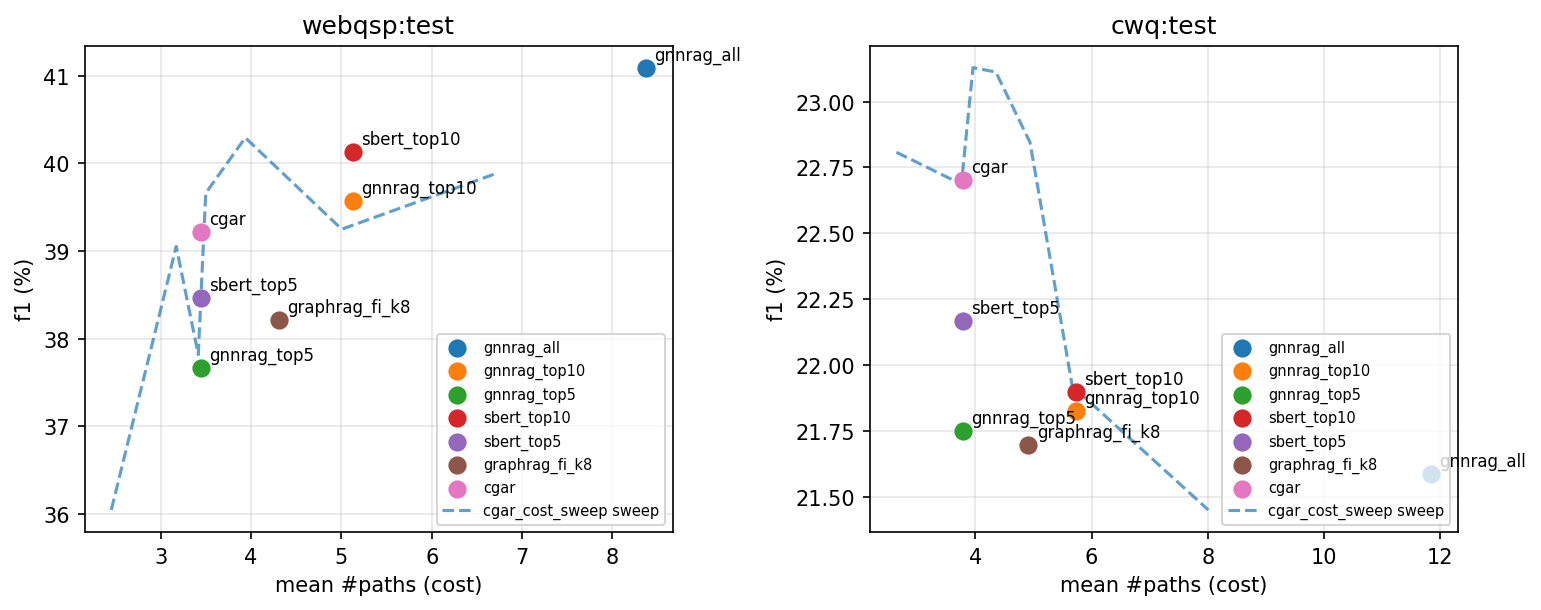

In [11]:
B06 = f'{RESULTS}/b06_main' + ('_v3' if CGAR_FLAGS else '')   # thư mục theo biến thể được chọn ở 03 (b06_main cũ = gốc, dùng lại được)
R06 = run_bench(B06, train=WEBQSP_TR, evals=[WEBQSP_TE, CWQ_TE],
                methods=['gnnrag_all','gnnrag_top10','gnnrag_top5','sbert_top10','sbert_top5','graphrag_fi','cgar'] + (['prism'] if RUN_PRISM else []),
                extra=f'--seeds 42 1337 2024 --sweep --dev-split 0.1 --cgar-max-paths {CGAR_BUDGET} --cgar-s2-steps {CGAR_S2_STEPS} {CGAR_FLAGS} ' + (f'--prism-teacher-cache {TEACHER_CACHE} ' if RUN_PRISM else '')
                      + f'--compare-ref gnnrag_all --n-bootstrap 10000 --quiet')
show(R06); show_cmp(R06)
for ds, by_m in R06['seeds'].items():
    for m in (('cgar','prism') if RUN_PRISM else ('cgar',)):
        sd = by_m.get(m, {}).get('f1', {}); print(ds, m, 'F1 = %.2f ± %.2f' % (sd.get('mean',0)*100, sd.get('std',0)*100))
        gate(sd.get('std', 1) < 0.01, f'{ds} {m}: std F1 theo seed < 1 pp')
from kgqa_bench.metrics import matched_cost_table
for ds in R06['summaries']:
    print(ds, 'matched-cost vs cgar:', matched_cost_table(R06['summaries'][ds], 'cgar', tol=0.75))
for name in ('cgar_cost_sweep', 'cgar_beta_sweep', 'prism_eps_sweep'):
    sw = pd.DataFrame(R06['train_logs'].get(name, []))
    if len(sw): print('\n' + name); display(sw.round(4))
_c = R06['train_logs'].get('cgar_cost_sweep', []); _p = R06['train_logs'].get('prism_eps_sweep', [])
gate(len({round(p['cost'], 1) for p in _c if p['dataset'] == 'webqsp:test'}) >= 3, 'cgar_cost_sweep tạo ≥ 3 mức cost khác nhau (đường Pareto thật; β-sweep lần 11/2026 phẳng 9.96–9.99)')
if RUN_PRISM: gate(len({round(p['cost'], 1) for p in _p if p['dataset'] == 'webqsp:test' and p['eps'] > 0}) >= 2, 'eps PRISM có làm cost thay đổi (lần 11/2026: phẳng = 3 ở mọi eps)')
rep06 = open(f'{B06}/report.md').read(); print(rep06.split('## Adaptivity')[-1].split('## Sweeps')[0][:800] if '## Adaptivity' in rep06 else '')
from IPython.display import Image; display(Image(f'{B06}/pareto.png'))

## 06b · Confidence-gated escalation (offline, không inference thêm)
**Mục tiêu:** GNN-RAG+RA trong paper tăng Hit bằng cách *bổ sung* evidence; CGAR hiện chỉ *bớt* evidence và mất ~2 pp F1 so với all. Vì AURC của CGAR tốt nhất bảng, thử chính sách 2 tầng: trả lời bằng CGAR nếu `confidence ≥ τ`, ngược lại dùng toàn bộ path của gnnrag_all. Mọi điểm trên đường τ tính từ hai file records đã có (cùng qid), cộng điểm `oracle` (escalate đúng câu mà all tốt hơn) làm cận trên.
**Đọc:** đường chỉ có giá trị ở đoạn nằm **trên** các điểm top-K cùng cost (tham chiếu cùng qid). Khoảng cách tới `oracle` cho biết confidence head bắt được bao nhiêu phần gain khả dĩ.
**Gate:** tồn tại τ với cost ≤ 60% cost của all mà F1 ≥ F1(all) − 0.5 pp; và điểm đó cao hơn top-K gần nhất cùng cost.


,tau,escalated_frac,cost,f1,coverage,hit_ctx
0,-inf,0.0000,3.4478,0.3921,0.6288,0.7961
1,0.0,0.0000,3.4478,0.3921,0.6288,0.7961
2,0.0599,0.0504,3.9251,0.3950,0.6358,0.8004
3,0.1289,0.1001,4.6880,0.3998,0.6462,0.8047
4,0.1889,0.1505,5.5283,0.4045,0.6572,0.8090
5,0.2708,0.2002,6.2494,0.4098,0.6728,0.8145
6,0.3559,0.2506,6.8667,0.4128,0.6860,0.8182
7,0.4564,0.3004,7.2543,0.4138,0.6955,0.8231
8,0.5312,0.3501,7.4994,0.4142,0.7010,0.8243
9,0.6269,0.3999,7.6296,0.4138,0.7044,0.8262


operating points:
  match_fallback_quality: τ=0.2708 escalate 20% cost 6.25 F1 40.98
  best_at_60pct_cost: τ=0.1289 escalate 10% cost 4.69 F1 39.98
  knee: τ=0.2708 escalate 20% cost 6.25 F1 40.98


,method,cost,f1,hit_ctx
0,cgar,3.4478,0.3921,0.7961
2,gnnrag_top5,3.4478,0.3767,0.7819
4,sbert_top5,3.4478,0.3847,0.7899
6,graphrag_fi_k8,4.3096,0.3821,0.7973
5,sbert_top10,5.1241,0.4013,0.8163
3,gnnrag_top10,5.1241,0.3957,0.8071
1,gnnrag_all,8.3692,0.4109,0.8323


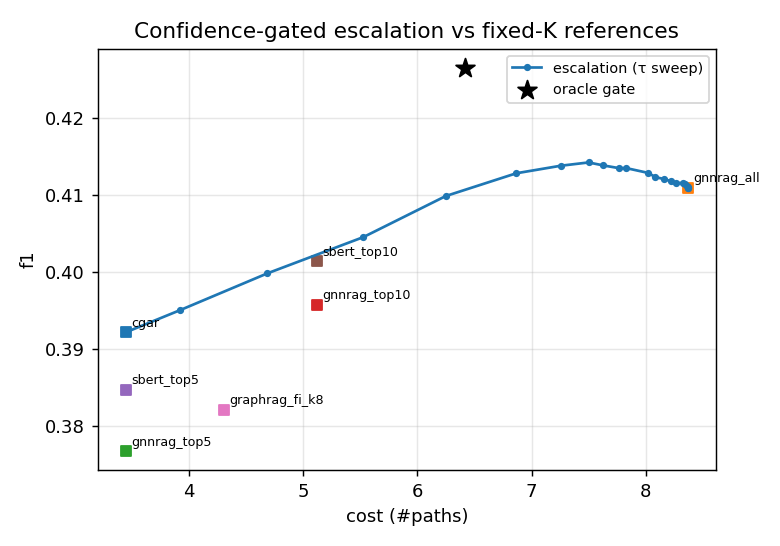

FAIL  có τ với cost ≤ 60% all (5.02) đạt F1 ≥ all − 0.5 pp (best 39.98@4.69 vs all 41.09@8.37)
PASS  điểm đó hơn top-K gần nhất cùng cost (graphrag_fi_k8: 38.21@4.31)
oracle gate: escalate 18% → F1 42.65 @ cost 6.42  (cận trên cho mọi gate trên 2 method này)


In [12]:
from kgqa_bench import escalation as E
from IPython.display import Image, display as _d
RE = E.run(B06, 'webqsp:test', primary='cgar', fallback='gnnrag_all', quality='f1', do_plot=True, verbose=False)
rows = pd.DataFrame(RE['rows']); display(rows[['tau','escalated_frac','cost','f1','coverage','hit_ctx']].round(4))
print('operating points:'); [print(f"  {k}: τ={v['tau']} escalate {v['escalated_frac']*100:.0f}% cost {v['cost']:.2f} F1 {v['f1']*100:.2f}") for k, v in RE['operating_points'].items()]
refs = pd.DataFrame(RE['references']).sort_values('cost'); display(refs[['method','cost','f1','hit_ctx']].round(4))
_d(Image(f"{B06}/escalation/escalation_webqsp_test_cgar_to_gnnrag_all.png"))
allrow = [r for r in RE['rows'] if r['tau'] == '+inf'][0]; orc = [r for r in RE['rows'] if r['tau'] == 'oracle'][0]
cheap = [r for r in RE['rows'] if r['tau'] not in ('oracle',) and r['cost'] <= 0.6 * allrow['cost']]
best = max(cheap, key=lambda r: r['f1']) if cheap else None
gate(best is not None and best['f1'] >= allrow['f1'] - 0.005, f"có τ với cost ≤ 60% all ({0.6*allrow['cost']:.2f}) đạt F1 ≥ all − 0.5 pp (best {best['f1']*100:.2f}@{best['cost']:.2f} vs all {allrow['f1']*100:.2f}@{allrow['cost']:.2f})" if best else 'không có điểm nào ≤ 60% cost')
near = min(RE['references'], key=lambda d: abs(d['cost'] - (best['cost'] if best else 0))) if (best and RE['references']) else None
gate(bool(near) and best['f1'] > near['f1'] + 0.005, f"điểm đó hơn top-K gần nhất cùng cost ({near['method'] if near else '-'}: {near['f1']*100:.2f}@{near['cost']:.2f})" if near else 'không có tham chiếu')
print(f"oracle gate: escalate {orc['escalated_frac']*100:.0f}% → F1 {orc['f1']*100:.2f} @ cost {orc['cost']:.2f}  (cận trên cho mọi gate trên 2 method này)")


## 06c · Phân tích offline A2–A4 (adaptivity thật, CI từng cặp, selective curve)
**A2** tách cost thấp do controller dừng sớm khỏi cost thấp do pool cạn: với mỗi câu tính số path có sẵn (cùng extraction) → `controller_stopped_early` = cost < min(n_paths, budget). Kèm F1 theo số ứng viên trong pool.
**A3** CI paired cho các cặp chưa có: CGAR vs sbert_top5, vs gnnrag_top5 (hiện chỉ có CI so với all).
**A4** đường selective answering (Hit-ctx theo coverage xếp theo confidence) cho mọi method có confidence — hình trung tâm của claim abstain.
**Gate:** tỉ lệ `controller_stopped_early` được báo cáo đúng nghĩa (nếu ≈0 thì không gọi CGAR là adaptive, trừ khi v3 learned-stop được chọn); CI CGAR − sbert_top5 không chứa 0 thì mới claim 'hơn SBERT'.


# Offline analysis — `webqsp:test` (/content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b06_main)

## A2. Adaptivity of `cgar` (budget 5)

cost histogram: {0: 1, 1: 346, 2: 199, 3: 214, 4: 113, 5: 755}
chosen_k histogram: {0: 1, 10: 28, 20: 12, 5: 751, 50: 836}

| category | n | frac |
|---|---|---|
| pool_limited | 957 | 0.588 |
| full_budget | 671 | 0.412 |

questions with more paths than budget: 0.412; mean cost when the controller stopped early: None

Reading: only `controller_stopped_early` is adaptivity attributable to the controller; `pool_limited` questions would have the same cost under any method.

## A2b. F1 / Hit-ctx by #candidates in the pool

| method | 1 (n) | 2-3 (n) | 4-5 (n) | 6-10 (n) | >10 (n) |
|---|---|---|---|---|---|
| cgar | 46.0 / 79.3 (444) | 44.7 / 85.7 (447) | 42.6 / 81.7 (230) | 34.5 / 74.1 (228) | 20.7 / 73.1 (279) |
| gnnrag_all | 45.9 / 79.3 (444) | 44.2 / 85.9 (447) | 40.6 / 83.0 (230) | 35.4 / 80.7 (228) | 33.4 / 87.5 (279) |
| gnnrag_top1

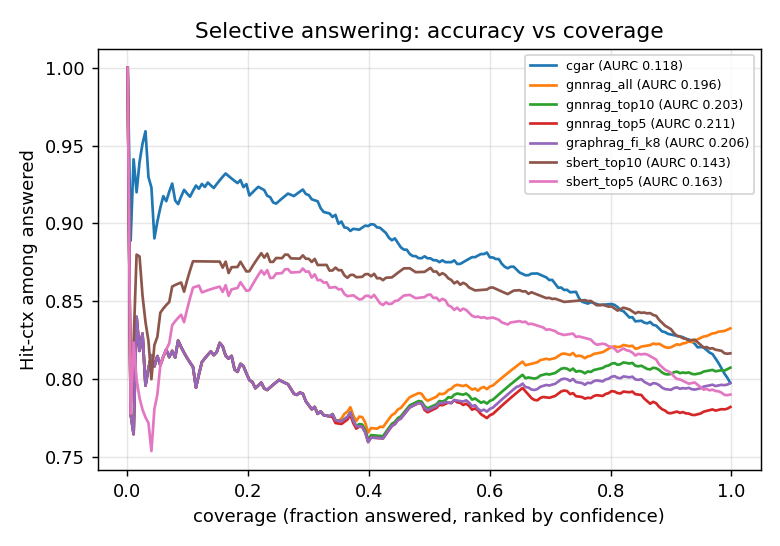

controller_stopped_early = 0.0% | pool_limited = 58.8% | full_budget = 41.2%
PASS  bản gốc: adaptivity = pool cạn → ghi caveat, không claim adaptive
CGAR − sbert_top5 F1: Δ=+0.75 CI=[+0.37,+1.12] p=0.0000
PASS  CGAR > sbert_top5 với CI không chứa 0 (gain đến từ controller, không chỉ embedding)
{'cgar': 0.118, 'gnnrag_all': 0.196, 'gnnrag_top10': 0.203, 'gnnrag_top5': 0.211, 'graphrag_fi_k8': 0.206, 'sbert_top10': 0.143, 'sbert_top5': 0.163}
PASS  AURC CGAR thấp nhất trong mọi method có confidence


In [13]:
from kgqa_bench import analysis as AN
RA = AN.run(B06, 'webqsp:test', eval_spec=WEBQSP_TE, budget=CGAR_BUDGET, primary='cgar',
            pairs=['cgar:sbert_top5','cgar:gnnrag_top5','cgar:gnnrag_top10','cgar:gnnrag_all'], n_bootstrap=10000, do_plot=True, verbose=False)
print(open(f"{B06}/analysis/analysis_webqsp_test.md").read())
from IPython.display import Image, display as _d; _d(Image(f"{B06}/analysis/selective_webqsp_test.png"))
cats = RA['adaptivity'].get('categories', {}); early = cats.get('controller_stopped_early', {}).get('frac', 0.0)
print(f"controller_stopped_early = {early*100:.1f}% | pool_limited = {cats.get('pool_limited',{}).get('frac',0)*100:.1f}% | full_budget = {cats.get('full_budget',{}).get('frac',0)*100:.1f}%")
gate(early >= 0.10 or not CGAR_FLAGS, 'controller tự dừng sớm ở ≥10% câu (adaptivity thật, không phải pool cạn)' if CGAR_FLAGS else 'bản gốc: adaptivity = pool cạn → ghi caveat, không claim adaptive')
cs = RA['pairwise'].get('cgar:sbert_top5', {}).get('f1', {}); b = cs.get('bootstrap', {})
if b: print(f"CGAR − sbert_top5 F1: Δ={b['delta']*100:+.2f} CI=[{b['ci_low']*100:+.2f},{b['ci_high']*100:+.2f}] p={b['p_value']:.4f}")
gate(bool(b) and b['ci_low'] > 0, 'CGAR > sbert_top5 với CI không chứa 0 (gain đến từ controller, không chỉ embedding)')
sel = RA['selective']; print({m: round(r['aurc'],3) for m, r in sel.items()})
gate('cgar' in sel and all(sel['cgar']['aurc'] <= r['aurc'] for r in sel.values()), 'AURC CGAR thấp nhất trong mọi method có confidence')


## 07 · Calibration và abstention
**Mục tiêu:** confidence của controller có dùng để từ chối trả lời không, và có hơn temperature scaling trên điểm GNN không.
**Output kỳ vọng:** max-GNN ECE 0.15–0.25; temp-scaled 0.05–0.10; CGAR/PRISM mục tiêu <0.08, AURC thấp nhất, sel_acc@80 > hit_ctx + 5 pp. Số ECE trong `PRISM_experiments.md` là placeholder, không dùng.
**Gate:** chỉ đánh giá ECE khi las_hit1 ≥ 0.2 (lần 11/2026: las_hit1 0.03 → ECE 0.06–0.08 của mọi phương pháp là tầm thường, isotonic GNN 0.024 thắng). AURC CGAR < top-10 là gate luôn hợp lệ.


=== webqsp:test ===


,hit_ctx,ece,ece_adaptive,mce,brier,aurc,sel_acc@80,sel_acc@50,overconf_rate
gnnrag_all,0.832,0.436,0.430,0.865,0.389,0.196,0.820,0.787,0.078
gnnrag_top10,0.807,0.411,0.405,0.779,0.373,0.203,0.810,0.783,0.078
gnnrag_top5,0.782,0.387,0.380,0.742,0.359,0.211,0.792,0.780,0.079
sbert_top10,0.816,0.198,0.199,0.791,0.193,0.143,0.847,0.871,0.036
sbert_top5,0.790,0.174,0.172,0.791,0.198,0.163,0.822,0.854,0.039
graphrag_fi_k8,0.797,0.401,0.395,0.768,0.368,0.206,0.801,0.781,0.078
cgar,0.796,0.221,0.217,0.568,0.218,0.118,0.848,0.878,0.067



=== cwq:test ===


,hit_ctx,ece,ece_adaptive,mce,brier,aurc,sel_acc@80,sel_acc@50,overconf_rate
gnnrag_all,0.658,0.298,0.291,0.565,0.325,0.288,0.656,0.678,0.157
gnnrag_top10,0.621,0.264,0.257,0.431,0.303,0.295,0.644,0.676,0.157
gnnrag_top5,0.580,0.232,0.231,0.380,0.287,0.306,0.621,0.669,0.160
sbert_top10,0.635,0.050,0.047,0.901,0.229,0.322,0.659,0.685,0.085
sbert_top5,0.600,0.049,0.049,0.901,0.238,0.353,0.624,0.649,0.093
graphrag_fi_k8,0.606,0.251,0.246,0.388,0.296,0.298,0.636,0.676,0.157
cgar,0.605,0.147,0.145,0.234,0.231,0.238,0.670,0.767,0.118


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

/content/drive/MyDrive/ThS/Research/colab/graph_rag/grl_rag.py:128: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.emb_dim = self.model.get_sentence_embedding_dimension()


[skip] exp4 (PRISM) — nhánh CGAR-only; calibration CGAR đọc từ bảng trên (ECE/AURC/sel_acc vs hit_ctx)
PASS  AURC CGAR < top-10 (selective answering; không phụ thuộc tỉ lệ dương)


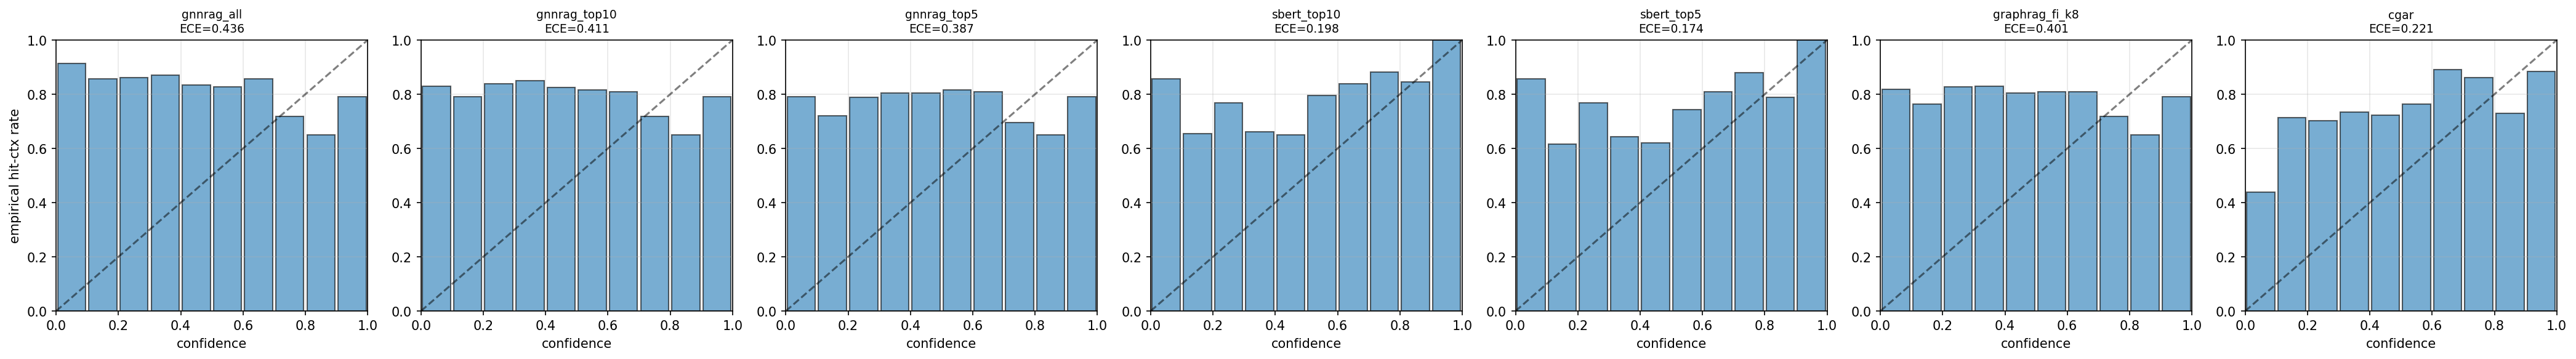

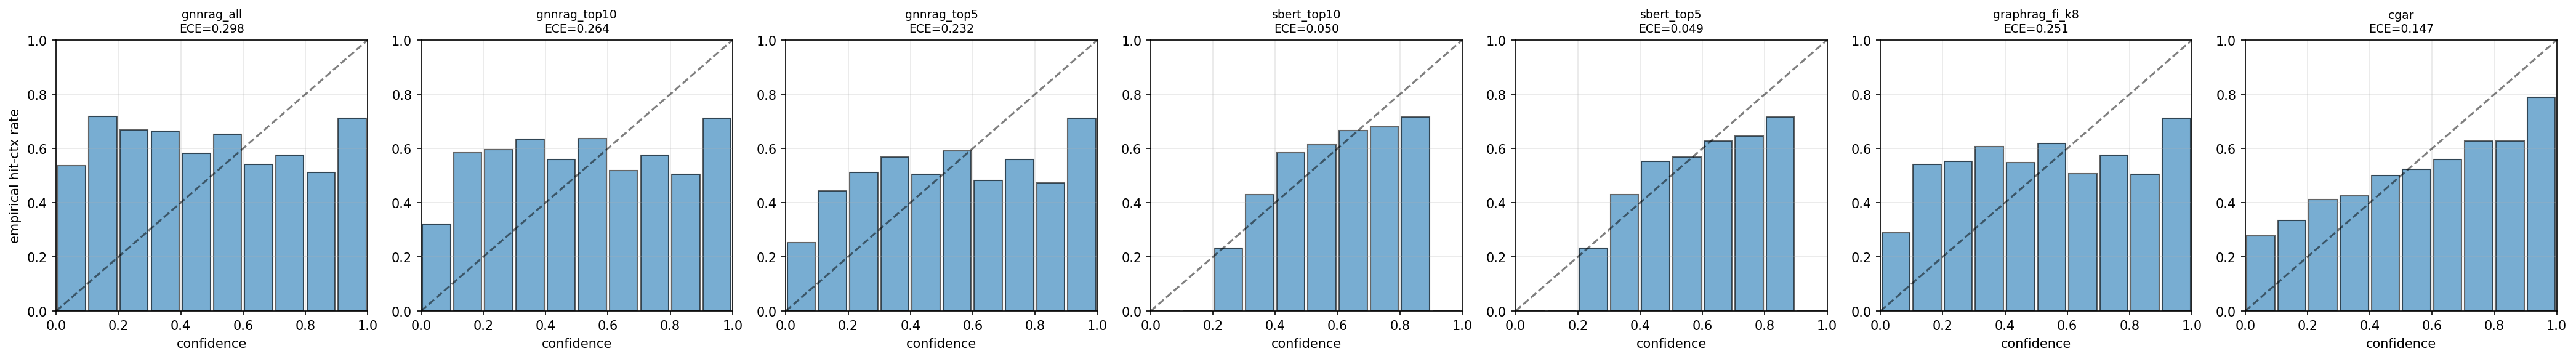

In [10]:
from kgqa_bench.data import load_rog_hf
from kgqa_bench.adapters import PrismVocab
from kgqa_bench.methods import PRISMMethod
from grl_rag import Embedder
from prism.config import CFG
from prism.experiments.exp4_calibration import run_exp4a_in_dist, run_exp4b_shift
B07 = f'{RESULTS}/b07_calibration'; os.makedirs(B07, exist_ok=True)

# ECE/AURC/sel_acc của mọi method đã có trong results của bước 06 (vs hit_ctx):
show(R06, cols=['hit_ctx','ece','ece_adaptive','mce','brier','aurc','sel_acc@80','sel_acc@50','overconf_rate'])

# Baseline công bằng (temp-scaled / isotonic trên điểm GNN), fit trên dev tách từ train:
emb = Embedder(model_name=EMB_MODEL)
from kgqa_bench.data import load_spec
tr = load_spec(WEBQSP_TR, cache_dir=DATA_CACHE); n_dev = int(len(tr)*0.1)
dev = type(tr)(tr.name, 'dev', tr.questions[-n_dev:], tr.source); tr.questions = tr.questions[:-n_dev]
te = load_spec(WEBQSP_TE, cache_dir=DATA_CACHE); cwq = load_spec(CWQ_TE, cache_dir=DATA_CACHE)
if RUN_PRISM:
    pm = PRISMMethod(emb, cfg=CFG, device=DEVICE).load(PRISM_CKPT, vocab_path=PRISM_CKPT + '.vocab.json')
    rep_a = run_exp4a_in_dist(pm.las, pm.samples_for(te), pm.samples_for(dev), CFG, out_dir=B07)
    rep_b = run_exp4b_shift(pm.las, pm.samples_for(dev), pm.samples_for(cwq), CFG, out_dir=B07)
base = R06['summaries']['webqsp:test'].get('prism', {}).get('las_hit1', 0.0)
if not RUN_PRISM:
    print('[skip] exp4 (PRISM) — nhánh CGAR-only; calibration CGAR đọc từ bảng trên (ECE/AURC/sel_acc vs hit_ctx)')
elif base < 0.2:
    print(f'WARN: las_hit1 = {base:.3f} < 0.2: ECE/Brier ở tỉ lệ dương thấp là tầm thường (dự đoán ~0 cho mọi câu cũng được ECE nhỏ). KHÔNG kết luận calibration trên pool này — chờ GNN features.')
else:
    gate(rep_a['PRISM (ours)']['ece'] < rep_a['Temp-scaled GNN']['ece'], 'PRISM ECE < temp-scaled GNN (in-dist)')
gate(R06['summaries']['webqsp:test']['cgar']['aurc'] < R06['summaries']['webqsp:test']['gnnrag_top10']['aurc'], 'AURC CGAR < top-10 (selective answering; không phụ thuộc tỉ lệ dương)')
from IPython.display import Image
for ds in ('webqsp_test','cwq_test'): display(Image(f'{B06}/reliability_{ds}.png'))

## 08 · LLM reader end-to-end và hallucination
**Mục tiêu:** retrieval tốt hơn có thành câu trả lời tốt hơn không; đo hallucination = `llm_unsupported_rate` (entity trả lời không có trong context) so với reader **không có context**.
**Output kỳ vọng:** no_retrieval: llm_hit thấp, unsupported cao; gnnrag_all cao nhất (Seminar 1: 83.7 Llama-2-7B); cgar/prism trong 1–2 pp của all với `n_tokens_prompt` thấp hơn ≥20%.
**Kết quả 11/2026 (Qwen2.5-7B, pool heuristic, 1000 câu đầu):** no_retrieval 0.476 > gnnrag_all 0.410 ≈ cgar 0.402 (p=0.48) > top5 0.203: context heuristic làm reader TỆ hơn không RAG, đúng pattern của paper tham chiếu. Đây là finding cho mục "RAG mitigates hallucination?": chất lượng retrieval quyết định. Kỳ vọng với GNN features: all ≈ 0.80+ > no_retrieval.
**Gate:** RAG(all) > no_retrieval; CGAR ≈ all (McNemar p > 0.05); unsupported_rate(cgar) < no_retrieval. Subset 1000 câu lấy ngẫu nhiên (`--subset-seed 0`), không lấy 1000 câu đầu.

In [7]:
READERS = ['Qwen/Qwen2.5-7B-Instruct', 'NousResearch/Meta-Llama-3.1-8B-Instruct']
# 'mistralai/Mistral-7B-Instruct-v0.3' bỏ 11/2026 (~3h GPU, Llama đã cho cùng kết luận); thêm lại khi cần reader thứ 3
# 'openai/gpt-oss-20b' cần ~40GB VRAM bf16 — thêm vào khi có A100-80GB
MAX_ITEMS = 1000
R08 = {}
def reader_dir(rd, prompt):   # chat = thư mục cũ (dùng lại); grounded = b08g_*; v3 → hậu tố _v3 vì CGAR khác checkpoint
    return f"{RESULTS}/{'b08' if prompt == 'chat' else 'b08g'}_reader_{rd.split('/')[-1]}" + ('_v3' if CGAR_FLAGS else '')
for rd in READERS:
  for prompt in READER_PROMPTS:
    out = reader_dir(rd, prompt)
    R08[(rd, prompt)] = run_bench(out, evals=[WEBQSP_TE], methods=['gnnrag_all','gnnrag_top5','sbert_top5','cgar'] + (['prism'] if RUN_PRISM else []),
                        extra=f'--max-items {MAX_ITEMS} --subset-seed 0 --cgar-ckpt {CGAR_CKPT} --cgar-max-paths {CGAR_BUDGET} {CGAR_FLAGS} ' + (f'--prism-ckpt {PRISM_CKPT} ' if RUN_PRISM else '')
                              + f'--reader hf:{rd}:{prompt} --no-retrieval-baseline --compare-ref gnnrag_all --quiet')
    # rescore offline (idempotent, no GPU): parser D2 + abstention-aware unsupported_rate. Also fixes dirs that were [skip]ped
    # (e.g. Llama chat llm_hit1 ~0.07 was the old parser). Legacy value kept as llm_unsupported_rate_legacy.
    import json
    for _m in [m for m in sys.modules if m in ('kgqa_bench.rescore', 'kgqa_bench.hallucination', 'prism.qa_text_eval')]: del sys.modules[_m]
    from kgqa_bench import rescore as RS; import prism.qa_text_eval as _qa
    assert hasattr(_qa, 'split_answer'), 'prism/qa_text_eval.py trên Drive là bản cũ -> sync lại (commit be5472e)'
    RS.rescore_dir(out, verbose=False); R08[(rd, prompt)] = json.load(open(f'{out}/results.json'))
    print('\n#####', rd, '| prompt =', prompt); show(R08[(rd, prompt)], cols=['cost','n_tokens_prompt','hit_ctx','llm_hit','llm_hit1','llm_f1','llm_abstained','llm_unsupported_rate','ece_llm','aurc_llm']); show_cmp(R08[(rd, prompt)])
    s = R08[(rd, prompt)]['summaries']['webqsp:test']
    d_rag = (s['gnnrag_all']['llm_hit'] - s['no_retrieval']['llm_hit']) * 100
    print(f'RAG(all) − no_retrieval = {d_rag:+.1f} pp llm_hit  (Qwen2.5-7B, pool heuristic 11/2026: −6.6 pp → RAG làm HẠI, đúng pattern paper tham chiếu PyPI/RAG)')
    gate(d_rag > 0, 'retrieval giúp reader hơn không-RAG (kỳ vọng PASS với GNN features, FAIL với pool heuristic → ghi thành finding)')
    gate(s['no_retrieval']['llm_hit'] < s['gnnrag_all']['llm_hit'] or s['gnnrag_top5']['llm_hit'] <= s['gnnrag_all']['llm_hit'] + 0.02, 'top5 ≤ all (nhiều context hơn không làm tệ hơn)')
    gate(s['cgar']['llm_unsupported_rate'] <= s['gnnrag_all']['llm_unsupported_rate'] + 0.01, f"CGAR không tăng unsupported_rate (trên câu đã trả lời, abstention đã tách) so với GNN-RAG-all ({s['cgar']['llm_unsupported_rate']:.3f} vs {s['gnnrag_all']['llm_unsupported_rate']:.3f}; so với no-RAG là tầm thường)")
    gate(s['cgar']['llm_hit'] >= s['sbert_top5']['llm_hit'], 'CGAR ≥ sbert_top5 trên llm_hit')
    c = R08[(rd, prompt)]['comparisons']['webqsp:test'].get('cgar_vs_gnnrag_all:llm_hit', {})
    gate(bool(c) and (c['bootstrap']['delta'] > 0 or not c['significant_0.05']), 'CGAR ≥ hoặc tương đương GNN-RAG-all trên llm_hit')
# D1: prompt grounded có giảm unsupported mà không mất quá nhiều hit? (so cùng reader, cùng qid)
for rd in READERS:
    if (rd, 'chat') in R08 and (rd, 'grounded') in R08:
        a, g = R08[(rd, 'chat')]['summaries']['webqsp:test'], R08[(rd, 'grounded')]['summaries']['webqsp:test']
        for m in ('gnnrag_all', 'cgar'):
            print(f"{rd.split('/')[-1]:>28s} {m:>10s}: unsupported chat {a[m]['llm_unsupported_rate']:.3f} → grounded {g[m]['llm_unsupported_rate']:.3f}"
                  f" | abstained {a[m].get('llm_abstained', 0):.3f} → {g[m].get('llm_abstained', 0):.3f} | llm_hit {a[m]['llm_hit']:.3f} → {g[m]['llm_hit']:.3f}")
        gate(g['cgar']['llm_unsupported_rate'] < a['cgar']['llm_unsupported_rate'] - 0.02, f"{rd.split('/')[-1]}: prompt grounded giảm unsupported của CGAR ≥ 2 pp")
        gate(g['cgar']['llm_hit'] >= a['cgar']['llm_hit'] - 0.03, f"{rd.split('/')[-1]}: prompt grounded không làm CGAR mất quá 3 pp llm_hit")
        # D1 finding 11/2026 (Qwen): grounded prompt -12 pp llm_hit, unsupported không giảm -> reader bỏ cuộc trên câu có evidence (over-abstention), không phải bớt bịa
        ans_g = 1 - g['cgar'].get('llm_abstained', 0)
        print(f"{rd.split('/')[-1]:>28s}       cgar: grounded answered {ans_g:.3f}; hit|answered {g['cgar']['llm_hit']/max(ans_g,1e-9):.3f} (chat {a['cgar']['llm_hit']:.3f})")

[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b08_reader_Qwen2.5-7B-Instruct đã có results.json

##### Qwen/Qwen2.5-7B-Instruct | prompt = chat

=== webqsp:test ===


,cost,n_tokens_prompt,hit_ctx,llm_hit,llm_hit1,llm_f1,llm_abstained,llm_unsupported_rate,ece_llm,aurc_llm
gnnrag_all,8.476,239.068,0.834,0.765,0.716,0.625,0.027,0.114,0.378,0.222
gnnrag_top5,3.462,124.976,0.782,0.751,0.713,0.574,0.020,0.110,0.366,0.226
sbert_top5,3.462,124.498,0.792,0.755,0.694,0.577,0.018,0.109,0.141,0.174
no_retrieval,0.000,41.342,0.000,0.474,0.390,0.283,0.002,0.974,NaN,NaN
cgar,3.462,123.070,0.805,0.757,0.723,0.583,0.025,0.116,0.209,0.150


,dataset,pair,n,delta,ci,p,mcnemar_p,sig
0,webqsp:test,gnnrag_top5_vs_gnnrag_all:f1,996,-3.46,"[-4.23,-2.74]",0.0000,NaN,True
1,webqsp:test,gnnrag_top5_vs_gnnrag_all:hit_ctx,996,-5.22,"[-6.63,-3.92]",0.0000,0.0000,True
2,webqsp:test,gnnrag_top5_vs_gnnrag_all:llm_hit,996,-1.41,"[-2.81,-0.10]",0.0408,0.0541,True
3,webqsp:test,sbert_top5_vs_gnnrag_all:f1,996,-2.65,"[-3.40,-1.94]",0.0000,NaN,True
4,webqsp:test,sbert_top5_vs_gnnrag_all:hit_ctx,996,-4.22,"[-5.52,-3.01]",0.0000,0.0000,True
5,webqsp:test,sbert_top5_vs_gnnrag_all:llm_hit,996,-1.00,"[-2.51,+0.50]",0.2052,0.2370,False
6,webqsp:test,no_retrieval_vs_gnnrag_all:f1,996,-42.00,"[-43.83,-40.20]",0.0000,NaN,True
7,webqsp:test,no_retrieval_vs_gnnrag_all:hit_ctx,996,-83.43,"[-85.74,-81.12]",0.0000,0.0000,True
8,webqsp:test,no_retrieval_vs_gnnrag_all:llm_hit,996,-29.12,"[-32.53,-25.70]",0.0000,0.0000,True
9,webqsp:test,cgar_vs_gnnrag_all:f1,996,-1.70,"[-2.38,-1.06]",0.0000,NaN,True


RAG(all) − no_retrieval = +29.1 pp llm_hit  (Qwen2.5-7B, pool heuristic 11/2026: −6.6 pp → RAG làm HẠI, đúng pattern paper tham chiếu PyPI/RAG)
PASS  retrieval giúp reader hơn không-RAG (kỳ vọng PASS với GNN features, FAIL với pool heuristic → ghi thành finding)
PASS  top5 ≤ all (nhiều context hơn không làm tệ hơn)
PASS  CGAR không tăng unsupported_rate (trên câu đã trả lời, abstention đã tách) so với GNN-RAG-all (0.116 vs 0.114; so với no-RAG là tầm thường)
PASS  CGAR ≥ sbert_top5 trên llm_hit
PASS  CGAR ≥ hoặc tương đương GNN-RAG-all trên llm_hit
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b08g_reader_Qwen2.5-7B-Instruct đã có results.json

##### Qwen/Qwen2.5-7B-Instruct | prompt = grounded

=== webqsp:test ===


,cost,n_tokens_prompt,hit_ctx,llm_hit,llm_hit1,llm_f1,llm_abstained,llm_unsupported_rate,ece_llm,aurc_llm
gnnrag_all,8.476,259.783,0.834,0.640,0.606,0.532,0.287,0.003,0.331,0.342
gnnrag_top5,3.462,146.976,0.782,0.609,0.583,0.481,0.314,0.006,0.305,0.352
sbert_top5,3.462,146.498,0.792,0.631,0.587,0.488,0.286,0.005,0.046,0.259
no_retrieval,0.000,63.342,0.000,0.002,0.002,0.001,0.988,0.012,NaN,NaN
cgar,3.462,145.406,0.803,0.620,0.602,0.493,0.306,0.003,0.213,0.273


,dataset,pair,n,delta,ci,p,mcnemar_p,sig
0,webqsp:test,gnnrag_top5_vs_gnnrag_all:f1,996,-3.46,"[-4.23,-2.74]",0.0000,NaN,True
1,webqsp:test,gnnrag_top5_vs_gnnrag_all:hit_ctx,996,-5.22,"[-6.63,-3.92]",0.0000,0.0000,True
2,webqsp:test,gnnrag_top5_vs_gnnrag_all:llm_hit,996,-3.01,"[-4.32,-1.80]",0.0000,0.0000,True
3,webqsp:test,sbert_top5_vs_gnnrag_all:f1,996,-2.65,"[-3.40,-1.94]",0.0000,NaN,True
4,webqsp:test,sbert_top5_vs_gnnrag_all:hit_ctx,996,-4.22,"[-5.52,-3.01]",0.0000,0.0000,True
5,webqsp:test,sbert_top5_vs_gnnrag_all:llm_hit,996,-0.90,"[-2.41,+0.50]",0.2716,0.2976,False
6,webqsp:test,no_retrieval_vs_gnnrag_all:f1,996,-42.00,"[-43.83,-40.20]",0.0000,NaN,True
7,webqsp:test,no_retrieval_vs_gnnrag_all:hit_ctx,996,-83.43,"[-85.74,-81.12]",0.0000,0.0000,True
8,webqsp:test,no_retrieval_vs_gnnrag_all:llm_hit,996,-63.76,"[-66.77,-60.74]",0.0000,0.0000,True
9,webqsp:test,cgar_vs_gnnrag_all:f1,996,-1.90,"[-2.56,-1.25]",0.0000,NaN,True


... (3 outputs left out)

RAG(all) − no_retrieval = +21.7 pp llm_hit  (Qwen2.5-7B, pool heuristic 11/2026: −6.6 pp → RAG làm HẠI, đúng pattern paper tham chiếu PyPI/RAG)
PASS  retrieval giúp reader hơn không-RAG (kỳ vọng PASS với GNN features, FAIL với pool heuristic → ghi thành finding)
PASS  top5 ≤ all (nhiều context hơn không làm tệ hơn)
FAIL  CGAR không tăng unsupported_rate (trên câu đã trả lời, abstention đã tách) so với GNN-RAG-all (0.190 vs 0.158; so với no-RAG là tầm thường)
PASS  CGAR ≥ sbert_top5 trên llm_hit
FAIL  CGAR ≥ hoặc tương đương GNN-RAG-all trên llm_hit
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b08g_reader_Meta-Llama-3.1-8B-Instruct đã có results.json

##### NousResearch/Meta-Llama-3.1-8B-Instruct | prompt = grounded

=== webqsp:test ===


,cost,n_tokens_prompt,hit_ctx,llm_hit,llm_hit1,llm_f1,llm_abstained,llm_unsupported_rate,ece_llm,aurc_llm
gnnrag_all,8.476,253.539,0.834,0.751,0.611,0.588,0.135,0.015,0.376,0.243
gnnrag_top5,3.462,144.236,0.782,0.725,0.581,0.533,0.153,0.014,0.356,0.249
sbert_top5,3.462,143.593,0.792,0.721,0.561,0.531,0.150,0.013,0.104,0.177
no_retrieval,0.000,63.259,0.000,0.347,0.283,0.216,0.294,0.706,NaN,NaN
cgar,3.462,143.003,0.803,0.727,0.581,0.539,0.161,0.015,0.184,0.169


,dataset,pair,n,delta,ci,p,mcnemar_p,sig
0,webqsp:test,gnnrag_top5_vs_gnnrag_all:f1,996,-3.46,"[-4.23,-2.74]",0.0000,NaN,True
1,webqsp:test,gnnrag_top5_vs_gnnrag_all:hit_ctx,996,-5.22,"[-6.63,-3.92]",0.0000,0.0000,True
2,webqsp:test,gnnrag_top5_vs_gnnrag_all:llm_hit,996,-2.61,"[-4.12,-1.10]",0.0012,0.0011,True
3,webqsp:test,sbert_top5_vs_gnnrag_all:f1,996,-2.65,"[-3.40,-1.94]",0.0000,NaN,True
4,webqsp:test,sbert_top5_vs_gnnrag_all:hit_ctx,996,-4.22,"[-5.52,-3.01]",0.0000,0.0000,True
5,webqsp:test,sbert_top5_vs_gnnrag_all:llm_hit,996,-3.01,"[-4.72,-1.31]",0.0006,0.0009,True
6,webqsp:test,no_retrieval_vs_gnnrag_all:f1,996,-42.00,"[-43.83,-40.20]",0.0000,NaN,True
7,webqsp:test,no_retrieval_vs_gnnrag_all:hit_ctx,996,-83.43,"[-85.74,-81.12]",0.0000,0.0000,True
8,webqsp:test,no_retrieval_vs_gnnrag_all:llm_hit,996,-40.36,"[-43.88,-36.75]",0.0000,0.0000,True
9,webqsp:test,cgar_vs_gnnrag_all:f1,996,-1.90,"[-2.56,-1.25]",0.0000,NaN,True


RAG(all) − no_retrieval = +40.4 pp llm_hit  (Qwen2.5-7B, pool heuristic 11/2026: −6.6 pp → RAG làm HẠI, đúng pattern paper tham chiếu PyPI/RAG)
PASS  retrieval giúp reader hơn không-RAG (kỳ vọng PASS với GNN features, FAIL với pool heuristic → ghi thành finding)
PASS  top5 ≤ all (nhiều context hơn không làm tệ hơn)
PASS  CGAR không tăng unsupported_rate (trên câu đã trả lời, abstention đã tách) so với GNN-RAG-all (0.015 vs 0.015; so với no-RAG là tầm thường)
PASS  CGAR ≥ sbert_top5 trên llm_hit
FAIL  CGAR ≥ hoặc tương đương GNN-RAG-all trên llm_hit
         Qwen2.5-7B-Instruct gnnrag_all: unsupported chat 0.114 → grounded 0.003 | abstained 0.027 → 0.287 | llm_hit 0.765 → 0.640
         Qwen2.5-7B-Instruct       cgar: unsupported chat 0.116 → grounded 0.003 | abstained 0.025 → 0.306 | llm_hit 0.757 → 0.620
PASS  Qwen2.5-7B-Instruct: prompt grounded giảm unsupported của CGAR ≥ 2 pp
FAIL  Qwen2.5-7B-Instruct: prompt grounded không làm CGAR mất quá 3 pp llm_hit
         Qwen2.5-7B-Instruct

## 08b · Hallucination / groundedness (offline trên records của 08)
**Mục tiêu:** tách *faithfulness* (câu trả lời có được graph evidence hỗ trợ) khỏi *correctness*. `llm_unsupported_rate` cũ chỉ kiểm tra entity có xuất hiện trong context (false negative kiểu "Alice works_at X, X located_in London → born in London"; alias bị tính là bịa).
**Cách đo:** mỗi entity trả lời = 1 claim → tầng 1 kiểm tra graph (endpoint của path topic→entity / chỉ là node trung gian / có trong subgraph nhưng không được retrieve / không có); tầng 2 so chuỗi quan hệ có hướng của path với reference proofs (topic→gold trong full subgraph, chỉ dùng lúc đánh giá) → SUPPORTED / UNSUPPORTED / UNCERTAIN (+ CONTRADICTED nếu bật judge).
**Output:** `results_gnn/b08_reader_*/hallucination/`: `report_*.md`, `hallucination.json`, `claims_*.jsonl`, `risk_coverage_*.png`, `review_sample_*.csv` (200 dòng cho human review, ưu tiên câu hai method bất đồng).
**Gate:** CGAR không tăng question-HR so với gnnrag_all (paired, p ≥ 0.05); AURC-hallucination của CGAR < gnnrag_all (confidence xếp hạng được hallucination). Grounded-correct rate báo cáo kèm llm_hit để tránh thắng nhờ abstain.



##### Qwen/Qwen2.5-7B-Instruct | prompt = chat


,n_answered,abstention_rate,entity_unsupported_rate,claim_hallucination_rate,question_hallucination_rate,question_hallucination_rate_strict,graph_proof_support_rate,uncertain_rate,llm_hit,grounded_correct_rate,grounded_answer_f1,correct_ungrounded_rate,aurc_hallucination,aurc_incorrect
gnnrag_all,911.0,0.027,0.124,0.053,0.114,0.241,0.947,0.089,0.765,0.722,0.609,0.043,0.136,0.157
gnnrag_top5,910.0,0.020,0.121,0.100,0.131,0.252,0.900,0.103,0.751,0.697,0.555,0.054,0.144,0.160
sbert_top5,914.0,0.018,0.119,0.081,0.118,0.254,0.919,0.119,0.755,0.709,0.561,0.046,0.089,0.136
cgar,903.0,0.025,0.128,0.085,0.120,0.236,0.915,0.099,0.757,0.714,0.566,0.043,0.082,0.105


error taxonomy:


,gnnrag_all,gnnrag_top5,sbert_top5,cgar
ok_grounded,719,694,706,711
candidate_omission,40,39,40,36
abstained,85,86,82,93
missing_kg_evidence,55,58,58,56
correct_ungrounded,43,54,46,43
reader_reasoning_failure,34,19,27,29
wrong_relation_evidence,9,6,3,5
reader_unsupported_generation,11,10,7,10
path_selection_failure,0,30,27,13


CGAR − all question-HR: Δ=+0.40 pp CI=[-1.20,+2.01] p=0.6718 McNemar p=0.7080
PASS  CGAR không tăng question-hallucination-rate so với GNN-RAG-all (paired)
PASS  AURC-hallucination CGAR 0.08168873667822904 < GNN-RAG-all 0.13598751850624644 (confidence xếp hạng được hallucination)
PASS  grounded-correct CGAR ≥ sbert_top5


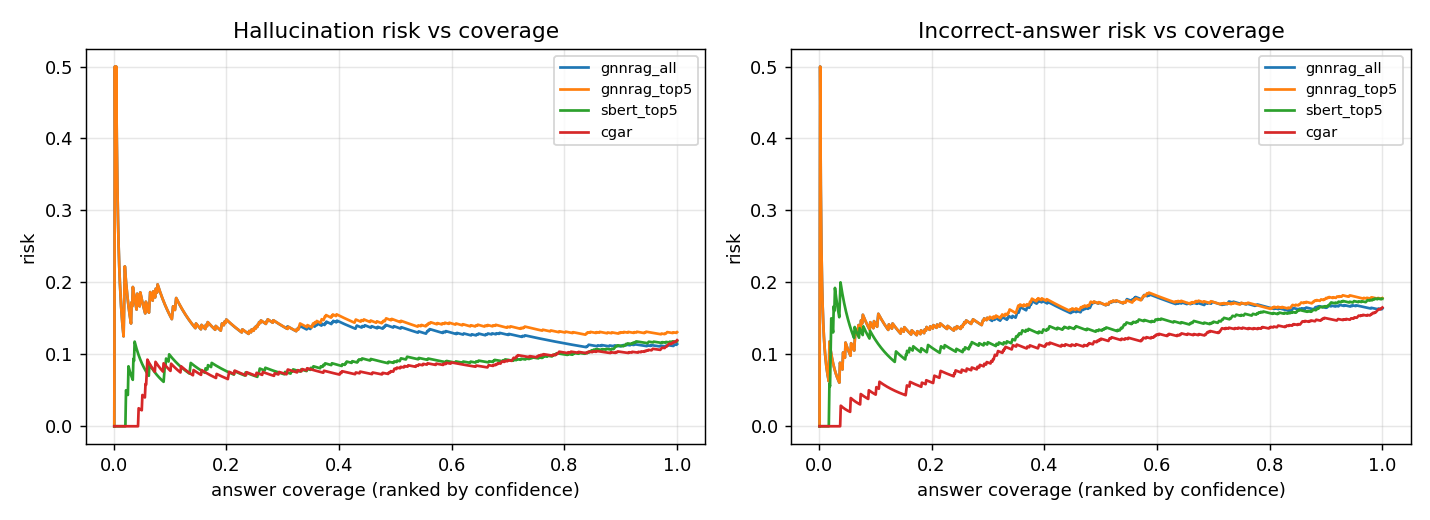


##### Qwen/Qwen2.5-7B-Instruct | prompt = grounded


,n_answered,abstention_rate,entity_unsupported_rate,claim_hallucination_rate,question_hallucination_rate,question_hallucination_rate_strict,graph_proof_support_rate,uncertain_rate,llm_hit,grounded_correct_rate,grounded_answer_f1,correct_ungrounded_rate,aurc_hallucination,aurc_incorrect
gnnrag_all,710.0,0.287,0.004,0.017,0.027,0.152,0.983,0.076,0.640,0.630,0.528,0.010,0.017,0.110
gnnrag_top5,683.0,0.314,0.008,0.016,0.028,0.129,0.984,0.075,0.609,0.602,0.478,0.007,0.018,0.111
sbert_top5,711.0,0.286,0.007,0.015,0.028,0.163,0.985,0.101,0.631,0.620,0.486,0.010,0.040,0.114
cgar,691.0,0.306,0.004,0.007,0.014,0.123,0.993,0.081,0.620,0.617,0.490,0.003,0.015,0.068


error taxonomy:


,gnnrag_all,gnnrag_top5,sbert_top5,cgar
ok_grounded,627,600,618,615
abstained,286,313,285,305
missing_kg_evidence,35,32,33,29
reader_reasoning_failure,22,14,18,19
correct_ungrounded,10,7,10,3
wrong_relation_evidence,2,2,3,2
reader_unsupported_generation,2,3,3,3
candidate_omission,12,12,16,15
path_selection_failure,0,13,10,5


CGAR − all question-HR: Δ=-0.90 pp CI=[-1.71,-0.10] p=0.0314 McNemar p=0.0490
PASS  CGAR không tăng question-hallucination-rate so với GNN-RAG-all (paired)
PASS  AURC-hallucination CGAR 0.014837786342354563 < GNN-RAG-all 0.01662427235373473 (confidence xếp hạng được hallucination)
FAIL  grounded-correct CGAR ≥ sbert_top5


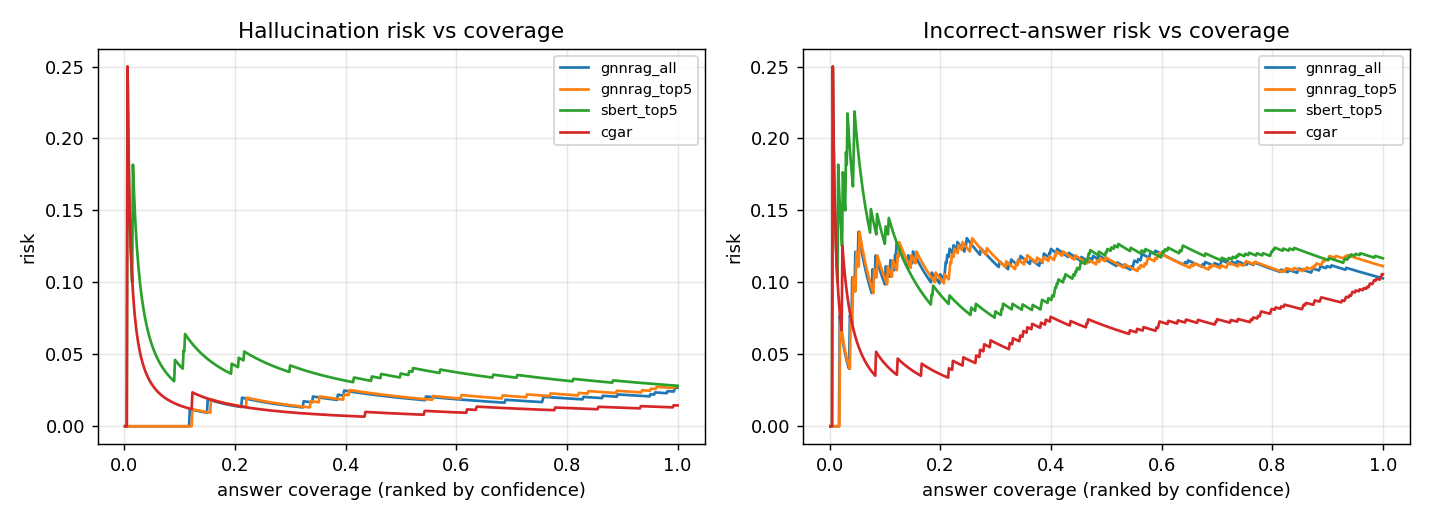


##### NousResearch/Meta-Llama-3.1-8B-Instruct | prompt = chat


,n_answered,abstention_rate,entity_unsupported_rate,claim_hallucination_rate,question_hallucination_rate,question_hallucination_rate_strict,graph_proof_support_rate,uncertain_rate,llm_hit,grounded_correct_rate,grounded_answer_f1,correct_ungrounded_rate,aurc_hallucination,aurc_incorrect
gnnrag_all,967.0,0.018,0.163,0.076,0.140,0.283,0.924,0.120,0.805,0.744,0.612,0.061,0.186,0.176
gnnrag_top5,960.0,0.020,0.180,0.159,0.157,0.282,0.841,0.122,0.769,0.704,0.555,0.065,0.190,0.182
sbert_top5,961.0,0.025,0.183,0.130,0.150,0.289,0.870,0.139,0.768,0.704,0.556,0.064,0.116,0.151
cgar,960.0,0.025,0.198,0.132,0.152,0.275,0.868,0.126,0.772,0.713,0.573,0.059,0.084,0.119


error taxonomy:


,gnnrag_all,gnnrag_top5,sbert_top5,cgar
ok_grounded,741,701,701,710
candidate_omission,39,42,44,47
correct_ungrounded,61,65,64,59
missing_kg_evidence,76,73,71,71
abstained,29,36,35,36
reader_unsupported_generation,15,11,12,10
reader_reasoning_failure,28,22,31,34
wrong_relation_evidence,7,8,6,6
path_selection_failure,0,38,32,23


CGAR − all question-HR: Δ=+1.10 pp CI=[-0.70,+2.91] p=0.2484 McNemar p=0.2664
PASS  CGAR không tăng question-hallucination-rate so với GNN-RAG-all (paired)
PASS  AURC-hallucination CGAR 0.08363038856890481 < GNN-RAG-all 0.18632738306469085 (confidence xếp hạng được hallucination)
PASS  grounded-correct CGAR ≥ sbert_top5


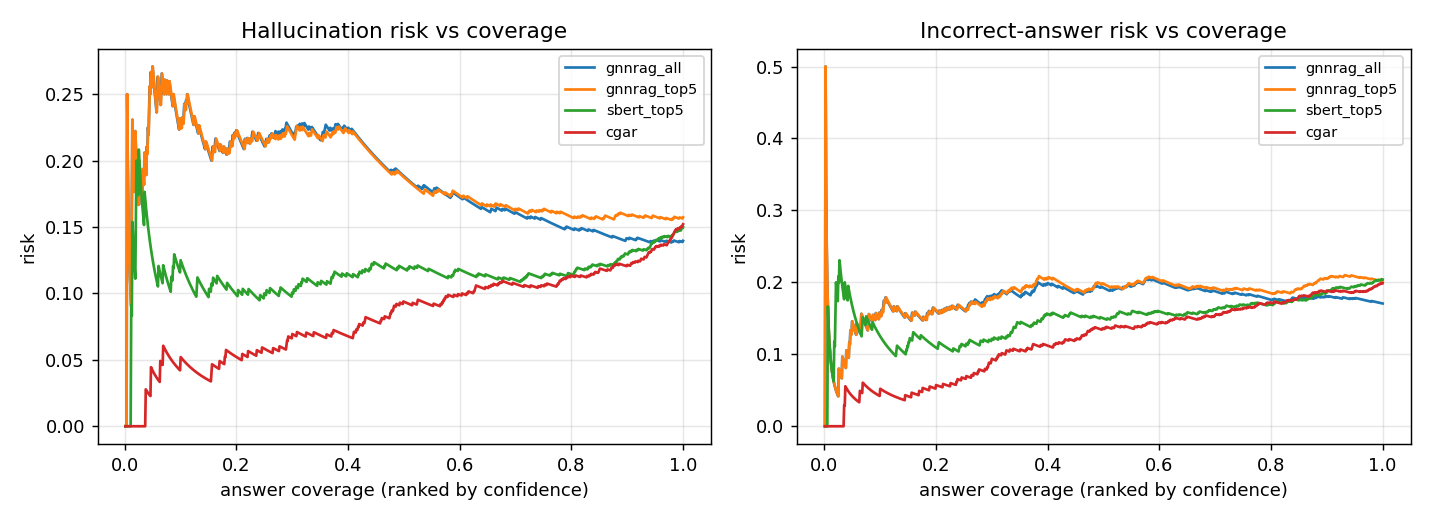


##### NousResearch/Meta-Llama-3.1-8B-Instruct | prompt = grounded


,n_answered,abstention_rate,entity_unsupported_rate,claim_hallucination_rate,question_hallucination_rate,question_hallucination_rate_strict,graph_proof_support_rate,uncertain_rate,llm_hit,grounded_correct_rate,grounded_answer_f1,correct_ungrounded_rate,aurc_hallucination,aurc_incorrect
gnnrag_all,862.0,0.135,0.018,0.078,0.186,0.299,0.922,0.087,0.751,0.629,0.581,0.122,0.183,0.128
gnnrag_top5,844.0,0.153,0.016,0.113,0.201,0.313,0.887,0.097,0.725,0.596,0.527,0.129,0.188,0.127
sbert_top5,847.0,0.150,0.016,0.096,0.194,0.322,0.904,0.109,0.721,0.594,0.526,0.127,0.217,0.121
cgar,836.0,0.161,0.018,0.092,0.194,0.313,0.908,0.108,0.727,0.593,0.535,0.134,0.174,0.085


error taxonomy:


,gnnrag_all,gnnrag_top5,sbert_top5,cgar
ok_grounded,626,594,592,591
candidate_omission,24,27,25,25
abstained,134,152,149,160
missing_kg_evidence,53,50,52,45
correct_ungrounded,122,128,126,133
wrong_relation_evidence,8,6,9,6
reader_unsupported_generation,3,3,2,3
reader_reasoning_failure,26,8,17,20
path_selection_failure,0,28,24,13


CGAR − all question-HR: Δ=+0.20 pp CI=[-1.81,+2.21] p=0.8764 McNemar p=0.9212
PASS  CGAR không tăng question-hallucination-rate so với GNN-RAG-all (paired)
PASS  AURC-hallucination CGAR 0.17366599908021396 < GNN-RAG-all 0.18339888916121372 (confidence xếp hạng được hallucination)
FAIL  grounded-correct CGAR ≥ sbert_top5


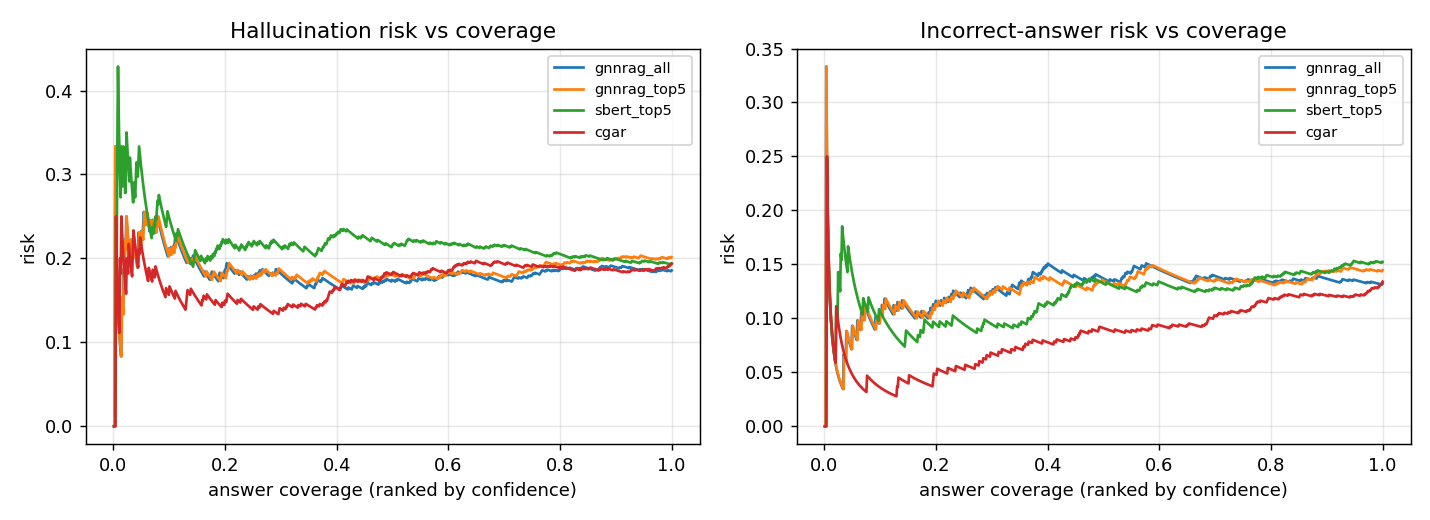

review_sample_*.csv → chia cho 2 người gán nhãn, đo precision/recall của detector trước khi viết claim

##### escalation @ reader Qwen/Qwen2.5-7B-Instruct


,tau,escalated_frac,cost,n_tokens_prompt,f1,llm_hit,llm_f1,llm_unsupported_rate
0,-inf,0.0000,3.4618,123.0703,0.4030,0.7570,0.5834,0.1162
1,0.0,0.0000,3.4618,123.0703,0.4030,0.7570,0.5834,0.1162
2,0.0677,0.0502,3.9478,134.3263,0.4061,0.7600,0.5877,0.1167
3,0.1449,0.1004,4.6847,149.4528,0.4088,0.7590,0.5918,0.1182
4,0.236,0.1506,5.4789,166.6958,0.4142,0.7560,0.5982,0.1183
5,0.3069,0.1998,6.2129,183.0412,0.4198,0.7550,0.6057,0.1172
6,0.405,0.2500,6.8384,196.3072,0.4220,0.7580,0.6104,0.1145
7,0.515,0.3002,7.1546,203.7299,0.4224,0.7580,0.6128,0.1143
8,0.6085,0.3504,7.5422,211.7189,0.4225,0.7600,0.6152,0.1109
9,0.6717,0.4006,7.7149,216.3614,0.4226,0.7631,0.6190,0.1155



##### escalation @ reader NousResearch/Meta-Llama-3.1-8B-Instruct


,tau,escalated_frac,cost,n_tokens_prompt,f1,llm_hit,llm_f1,llm_unsupported_rate
0,-inf,0.0000,3.4618,120.6968,0.4030,0.7721,0.5881,0.1900
1,0.0,0.0000,3.4618,120.6968,0.4030,0.7721,0.5881,0.1900
2,0.0677,0.0502,3.9478,131.4147,0.4061,0.7741,0.5923,0.1870
3,0.1449,0.1004,4.6847,146.0050,0.4088,0.7771,0.5956,0.1810
4,0.236,0.1506,5.4789,162.7159,0.4142,0.7801,0.6054,0.1821
5,0.3069,0.1998,6.2129,178.5020,0.4198,0.7811,0.6146,0.1779
6,0.405,0.2500,6.8384,191.3574,0.4220,0.7871,0.6184,0.1728
7,0.515,0.3002,7.1546,198.5341,0.4224,0.7962,0.6230,0.1705
8,0.6085,0.3504,7.5422,206.3353,0.4225,0.7972,0.6247,0.1706
9,0.6717,0.4006,7.7149,210.8133,0.4226,0.7972,0.6259,0.1693


In [16]:
from kgqa_bench import hallucination as H
R08H = {}
for rd in READERS:
  for prompt in READER_PROMPTS:
    out = reader_dir(rd, prompt)
    if not os.path.exists(f'{out}/results.json'): print('[skip]', out); continue
    res = H.run(out, [WEBQSP_TE], methods=['gnnrag_all','gnnrag_top5','sbert_top5','cgar'] + (['prism'] if RUN_PRISM else []),
                ref='gnnrag_all', review_n=200, n_bootstrap=10000, verbose=False)
    dsk = list(res['datasets'])[0]; S = res['datasets'][dsk]['summaries']; C = res['datasets'][dsk]['comparisons']
    R08H[(rd, prompt)] = res
    print('\n#####', rd, '| prompt =', prompt)
    display(pd.DataFrame(S).T[['n_answered','abstention_rate','entity_unsupported_rate','claim_hallucination_rate','question_hallucination_rate',
                               'question_hallucination_rate_strict','graph_proof_support_rate','uncertain_rate','llm_hit','grounded_correct_rate',
                               'grounded_answer_f1','correct_ungrounded_rate','aurc_hallucination','aurc_incorrect']].astype(float).round(3))
    print('error taxonomy:'); display(pd.DataFrame({m: s['error_taxonomy'] for m, s in S.items()}).fillna(0).astype(int))
    c = C.get('cgar', {}).get('hallucinated', {}); b = c.get('bootstrap', {})
    if b: print(f"CGAR − all question-HR: Δ={b['delta']*100:+.2f} pp CI=[{b['ci_low']*100:+.2f},{b['ci_high']*100:+.2f}] p={b['p_value']:.4f} McNemar p={c['mcnemar']['p_value']:.4f}")
    gate(bool(b) and (b['delta'] <= 0 or b['p_value'] >= 0.05), 'CGAR không tăng question-hallucination-rate so với GNN-RAG-all (paired)')
    gate('aurc_hallucination' in S.get('cgar', {}) and S['cgar']['aurc_hallucination'] < S['gnnrag_all']['aurc_hallucination'],
         f"AURC-hallucination CGAR {S.get('cgar',{}).get('aurc_hallucination')} < GNN-RAG-all {S['gnnrag_all'].get('aurc_hallucination')} (confidence xếp hạng được hallucination)")
    gate(S['cgar']['grounded_correct_rate'] >= S['sbert_top5']['grounded_correct_rate'], 'grounded-correct CGAR ≥ sbert_top5')
    from IPython.display import Image, display as _d; _d(Image(f"{out}/hallucination/risk_coverage_{dsk.replace(':','_')}.png"))
print('review_sample_*.csv → chia cho 2 người gán nhãn, đo precision/recall của detector trước khi viết claim')
# escalation ở mức reader: cùng 1000 qid, chuyển sang gnnrag_all khi CGAR conf < τ → llm_hit / unsupported / token thật
from kgqa_bench import escalation as E
for rd in READERS:
    out = reader_dir(rd, 'chat')
    if not os.path.exists(f'{out}/results.json'): continue
    RE8 = E.run(out, 'webqsp:test', primary='cgar', fallback='gnnrag_all', quality='llm_hit', refs=['gnnrag_top5','sbert_top5'], do_plot=False, verbose=False)
    print('\n##### escalation @ reader', rd); display(pd.DataFrame(RE8['rows'])[['tau','escalated_frac','cost','n_tokens_prompt','f1','llm_hit','llm_f1','llm_unsupported_rate']].round(4))


## 08c · CGAR-G: ít đường hơn, đúng hơn, ít bịa hơn GNN-RAG-all
**Vấn đề (lần 3 + P9):** CGAR budget 5 thua all đúng ở 17% câu có > 10 ứng viên (F1 20.7 so với 33.4) và bằng/hơn ở phần còn lại; reader zero-shot bỏ sót 4–7 pp câu có đáp án trong context và thêm entity không có path (QHR 0.11–0.14 ở all).
**Giải pháp, ba phần, mỗi phần có ablation riêng:**
1. `cgar_esc` (retrieval): CGAR(5) rồi **escalate** sang toàn bộ path khi > 10 ứng viên hoặc confidence < τ (τ = phân vị 20% trên dev, không nhìn test). Confidence giữ của CGAR.
2. Prompt `cand`: liệt kê **ứng viên = đích của các path** đã đưa, yêu cầu chọn trong danh sách; không cho "unknown" (grounded prompt đã thất bại vì bỏ cuộc).
3. `--reader-verify`: chỉ giữ entity trả lời trùng ứng viên; nếu không còn gì thì lấy ứng viên đầu (path liên quan nhất). Raw text giữ ở `llm_pred_raw`; P9 vẫn đo được trên cả hai.
**So sánh:** hàng tham chiếu là GNN-RAG như công bố (all + prompt chat). Hàng công bằng là all với cùng prompt/verify. Cả hai đều phải in ra.
**Gate:** (a) retrieval: F1(cgar_esc) ≥ F1(all) − 0.3, hit_ctx ≥ all − 1 pp, cost ≤ 80% all; (b) reader: llm_hit(cgar_esc, cand+verify) > llm_hit(all, chat) với CI không chứa 0; (c) công bằng: cgar_esc không thua all cùng cand+verify quá 0.5 pp có ý nghĩa; (d) QHR (P9) của cgar_esc cand+verify < all chat.


In [8]:
# ==== 08c. CGAR-G ====
# (a) retrieval-only, full test, hai dataset: cgar_esc so với all / top10 / cgar. tau chọn trên dev (carved từ train), ghi vào train_logs.
B06D = f'{RESULTS}/b06d_cgar_esc'
ESC_FLAGS = '--cgar-esc-ncand 10 --cgar-esc-frac 0.2 --cgar-esc-fallback all'
R06D = run_bench(B06D, train=WEBQSP_TR, evals=[WEBQSP_TE, CWQ_TE], methods=['gnnrag_all','gnnrag_top10','sbert_top5','cgar','cgar_esc'],
                 extra=f'--dev-split 0.1 --cgar-ckpt {CGAR_CKPT} --cgar-max-paths {CGAR_BUDGET} {CGAR_FLAGS} {ESC_FLAGS} --compare-ref gnnrag_all --quiet')
show(R06D, cols=['n','f1','cov','prec','hit_ctx','cost','n_tokens','escalated','ece','aurc','sel_acc@80']); show_cmp(R06D)
ESC_TAU = R06D['train_logs'].get('cgar_esc_tau@seed42', {}).get('tau'); print('tau (dev quantile 0.2):', ESC_TAU)
ESC_FLAGS_R = f'--cgar-esc-ncand 10 --cgar-esc-fallback all' + (f' --cgar-esc-tau {ESC_TAU}' if ESC_TAU is not None else '')   # reader runs: cùng tau, không nạp lại train
for dsk in R06D['summaries']:
    s = R06D['summaries'][dsk]; e, a = s['cgar_esc'], s['gnnrag_all']
    print(f'--- {dsk}: cgar_esc F1 {e["f1"]*100:.1f} @ {e["cost"]:.2f} (escalated {e["escalated"]*100:.0f}%) | all {a["f1"]*100:.1f} @ {a["cost"]:.2f} | cgar {s["cgar"]["f1"]*100:.1f} @ {s["cgar"]["cost"]:.2f}')
    gate(e['f1'] >= a['f1'] - 0.003, f'{dsk}: F1 cgar_esc >= all - 0.3 pp')
    gate(e['hit_ctx'] >= a['hit_ctx'] - 0.01, f'{dsk}: hit_ctx cgar_esc >= all - 1 pp ({e["hit_ctx"]:.3f} vs {a["hit_ctx"]:.3f})')
    gate(e['cost'] <= 0.8 * a['cost'], f'{dsk}: cost cgar_esc <= 80% all ({e["cost"]:.2f} vs {a["cost"]:.2f})')

# (b) reader: prompt cand + verify, cùng 1000 câu/seed 0 như 08. Thư mục b08c_*. (c) verify offline trên run chat cũ -> b08v_* (không GPU).
import shutil
from kgqa_bench import rescore as RS
from kgqa_bench.metrics import compare_records
def recs_of(out, method): return [json.loads(l) for l in open(f'{out}/records_webqsp_test_{method}.jsonl')]
R08C, R08V = {}, {}
for rd in READERS:
    tag = rd.split('/')[-1]
    out_c = f'{RESULTS}/b08c_reader_{tag}'
    R08C[rd] = run_bench(out_c, evals=[WEBQSP_TE], methods=['gnnrag_all','gnnrag_top5','sbert_top5','cgar','cgar_esc'],
                         extra=f'--max-items {MAX_ITEMS} --subset-seed 0 --cgar-ckpt {CGAR_CKPT} --cgar-max-paths {CGAR_BUDGET} {CGAR_FLAGS} {ESC_FLAGS_R} '
                               f'--reader hf:{rd}:cand --reader-verify --no-retrieval-baseline --compare-ref gnnrag_all --quiet')
    out_chat = reader_dir(rd, 'chat'); out_v = f'{RESULTS}/b08v_reader_{tag}'
    if os.path.exists(f'{out_chat}/results.json'):
        if not os.path.exists(f'{out_v}/results.json'): shutil.copytree(out_chat, out_v)
        RS.rescore_dir(out_v, verbose=False, verify=True); R08V[rd] = load_results(out_v)
    # bảng tổng hợp: tham chiếu = GNN-RAG như công bố (all, chat); các hàng còn lại cùng 1000 câu
    rows = {}
    if (rd, 'chat') in R08: rows['all | chat (GNN-RAG công bố)'] = R08[(rd, 'chat')]['summaries']['webqsp:test']['gnnrag_all']
    if rd in R08V:
        for m in ('gnnrag_all', 'cgar'): rows[f'{m} | chat+verify'] = R08V[rd]['summaries']['webqsp:test'][m]
    for m in ('gnnrag_all', 'gnnrag_top5', 'sbert_top5', 'cgar', 'cgar_esc'): rows[f'{m} | cand+verify'] = R08C[rd]['summaries']['webqsp:test'][m]
    print('\n#####', tag); display(pd.DataFrame(rows).T[['cost','n_tokens_prompt','hit_ctx','llm_hit','llm_hit1','llm_f1','llm_fallback','llm_abstained','aurc_llm']].round(3))
    # so cặp xuyên thư mục (cùng qid): cgar_esc cand+verify so với all chat (claim chính) và so với all cand+verify (công bằng)
    esc = recs_of(out_c, 'cgar_esc'); allc = recs_of(out_c, 'gnnrag_all')
    pairs = {'cgar_esc(cand+verify) - all(cand+verify)': (esc, allc)}
    if (rd, 'chat') in R08: pairs['cgar_esc(cand+verify) - all(chat, công bố)'] = (esc, recs_of(out_chat, 'gnnrag_all'))
    if rd in R08V: pairs['cgar(chat+verify) - all(chat)'] = (recs_of(out_v, 'cgar'), recs_of(out_chat, 'gnnrag_all'))
    for name, (A, B) in pairs.items():
        for met in ('llm_hit', 'llm_f1'):
            c = compare_records(A, B, met, n_bootstrap=10000); b = c['bootstrap']
            print(f"{name:48s} [{met}] Δ={b['delta']*100:+.2f} CI=[{b['ci_low']*100:+.2f},{b['ci_high']*100:+.2f}] p={b['p_value']:.4f} n={c['n']}")
    sc = R08C[rd]['summaries']['webqsp:test']
    if (rd, 'chat') in R08:
        c = compare_records(esc, recs_of(out_chat, 'gnnrag_all'), 'llm_hit', n_bootstrap=10000)['bootstrap']
        gate(c['ci_low'] > 0, f'{tag}: llm_hit cgar_esc(cand+verify) > all(chat) với CI không chứa 0 (Δ={c["delta"]*100:+.2f})')
    c = compare_records(esc, allc, 'llm_hit', n_bootstrap=10000)['bootstrap']
    gate(c['delta'] >= -0.005 or c['ci_high'] > 0, f'{tag}: công bằng — cgar_esc không thua all cùng cand+verify (Δ={c["delta"]*100:+.2f} [{c["ci_low"]*100:+.2f},{c["ci_high"]*100:+.2f}])')
    gate(sc['cgar_esc']['cost'] <= 0.8 * sc['gnnrag_all']['cost'], f'{tag}: cost cgar_esc {sc["cgar_esc"]["cost"]:.2f} <= 80% all {sc["gnnrag_all"]["cost"]:.2f}')
    gate(sc['cgar_esc']['llm_fallback'] <= 0.05, f'{tag}: fallback (không entity nào trùng ứng viên) <= 5% ({sc["cgar_esc"]["llm_fallback"]:.3f})')
print('QHR / grounded-correct của các thư mục b08c_*, b08v_* -> chạy P9 (tự nhận prefix b08c = cand+verify, b08v = chat+verify).')


[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b06d_cgar_esc đã có results.json

=== webqsp:test ===


,n,f1,cov,prec,hit_ctx,cost,n_tokens,escalated,ece,aurc,sel_acc@80
gnnrag_all,1628.0,0.411,0.720,0.339,0.832,8.369,109.553,NaN,0.436,0.196,0.820
gnnrag_top10,1628.0,0.396,0.666,0.338,0.807,5.124,62.219,NaN,0.411,0.203,0.810
sbert_top5,1628.0,0.385,0.619,0.344,0.790,3.448,40.461,NaN,0.174,0.163,0.822
cgar,1628.0,0.391,0.627,0.354,0.795,3.448,40.814,NaN,0.186,0.119,0.846
cgar_esc,1628.0,0.413,0.691,0.348,0.822,7.276,94.243,0.241,0.209,0.112,0.859



=== cwq:test ===


,n,f1,cov,prec,hit_ctx,cost,n_tokens,escalated,ece,aurc,sel_acc@80
gnnrag_all,3531.0,0.216,0.621,0.146,0.658,11.844,192.292,NaN,0.298,0.288,0.656
gnnrag_top10,3531.0,0.218,0.578,0.149,0.621,5.729,83.771,NaN,0.264,0.295,0.644
sbert_top5,3531.0,0.222,0.551,0.154,0.600,3.779,54.555,NaN,0.049,0.353,0.624
cgar,3531.0,0.225,0.552,0.157,0.602,3.778,53.440,NaN,0.157,0.243,0.670
cgar_esc,3531.0,0.223,0.590,0.153,0.633,9.583,154.735,0.232,0.184,0.239,0.676


,dataset,pair,n,delta,ci,p,mcnemar_p,sig
0,webqsp:test,gnnrag_top10_vs_gnnrag_all:f1,1628,-1.52,"[-1.84,-1.21]",0.0000,NaN,True
1,webqsp:test,gnnrag_top10_vs_gnnrag_all:hit_ctx,1628,-2.52,"[-3.32,-1.78]",0.0000,0.0,True
2,webqsp:test,sbert_top5_vs_gnnrag_all:f1,1628,-2.63,"[-3.19,-2.07]",0.0000,NaN,True
3,webqsp:test,sbert_top5_vs_gnnrag_all:hit_ctx,1628,-4.24,"[-5.22,-3.32]",0.0000,0.0,True
4,webqsp:test,cgar_vs_gnnrag_all:f1,1628,-1.99,"[-2.51,-1.49]",0.0000,NaN,True
5,webqsp:test,cgar_vs_gnnrag_all:hit_ctx,1628,-3.75,"[-4.73,-2.89]",0.0000,0.0,True
6,webqsp:test,cgar_esc_vs_gnnrag_all:f1,1628,0.23,"[-0.01,+0.45]",0.0644,NaN,False
7,webqsp:test,cgar_esc_vs_gnnrag_all:hit_ctx,1628,-0.98,"[-1.47,-0.55]",0.0000,0.0,True
8,cwq:test,gnnrag_top10_vs_gnnrag_all:f1,3531,0.24,"[+0.10,+0.38]",0.0024,NaN,True
9,cwq:test,gnnrag_top10_vs_gnnrag_all:hit_ctx,3531,-3.71,"[-4.36,-3.09]",0.0000,0.0,True


tau (dev quantile 0.2): 0.31475372910499577
--- webqsp:test: cgar_esc F1 41.3 @ 7.28 (escalated 24%) | all 41.1 @ 8.37 | cgar 39.1 @ 3.45
PASS  webqsp:test: F1 cgar_esc >= all - 0.3 pp
PASS  webqsp:test: hit_ctx cgar_esc >= all - 1 pp (0.822 vs 0.832)
FAIL  webqsp:test: cost cgar_esc <= 80% all (7.28 vs 8.37)
--- cwq:test: cgar_esc F1 22.3 @ 9.58 (escalated 23%) | all 21.6 @ 11.84 | cgar 22.5 @ 3.78
PASS  cwq:test: F1 cgar_esc >= all - 0.3 pp
FAIL  cwq:test: hit_ctx cgar_esc >= all - 1 pp (0.633 vs 0.658)
FAIL  cwq:test: cost cgar_esc <= 80% all (9.58 vs 11.84)
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b08c_reader_Qwen2.5-7B-Instruct đã có results.json

##### Qwen2.5-7B-Instruct


,cost,n_tokens_prompt,hit_ctx,llm_hit,llm_hit1,llm_f1,llm_fallback,llm_abstained,aurc_llm
all | chat (GNN-RAG công bố),8.476,239.068,0.834,0.765,0.716,0.625,NaN,0.027,0.222
gnnrag_all | chat+verify,8.476,239.068,0.834,0.770,0.728,0.627,0.063,0.027,0.229
cgar | chat+verify,3.462,123.070,0.805,0.764,0.737,0.589,0.067,0.025,0.135
gnnrag_all | cand+verify,8.476,299.827,0.834,0.789,0.725,0.632,0.028,0.001,0.211
gnnrag_top5 | cand+verify,3.462,173.029,0.782,0.765,0.720,0.581,0.039,0.001,0.217
sbert_top5 | cand+verify,3.462,174.398,0.792,0.772,0.694,0.585,0.033,0.001,0.166
cgar | cand+verify,3.462,171.967,0.803,0.773,0.738,0.594,0.042,0.001,0.126
cgar_esc | cand+verify,7.422,265.872,0.830,0.791,0.741,0.630,0.030,0.001,0.121


cgar_esc(cand+verify) - all(cand+verify)         [llm_hit] Δ=+0.20 CI=[-0.70,+1.10] p=0.7534 n=996
cgar_esc(cand+verify) - all(cand+verify)         [llm_f1] Δ=-0.29 CI=[-1.17,+0.61] p=0.5012 n=996
cgar_esc(cand+verify) - all(chat, công bố)       [llm_hit] Δ=+2.61 CI=[+0.90,+4.32] p=0.0030 n=996
cgar_esc(cand+verify) - all(chat, công bố)       [llm_f1] Δ=+0.46 CI=[-1.04,+1.96] p=0.5556 n=996
cgar(chat+verify) - all(chat)                    [llm_hit] Δ=-0.10 CI=[-1.81,+1.61] p=0.9610 n=996
cgar(chat+verify) - all(chat)                    [llm_f1] Δ=-3.63 CI=[-5.18,-2.09] p=0.0000 n=996
PASS  Qwen2.5-7B-Instruct: llm_hit cgar_esc(cand+verify) > all(chat) với CI không chứa 0 (Δ=+2.61)
PASS  Qwen2.5-7B-Instruct: công bằng — cgar_esc không thua all cùng cand+verify (Δ=+0.20 [-0.70,+1.10])
FAIL  Qwen2.5-7B-Instruct: cost cgar_esc 7.42 <= 80% all 8.48
PASS  Qwen2.5-7B-Instruct: fallback (không entity nào trùng ứng viên) <= 5% (0.030)
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/r

,cost,n_tokens_prompt,hit_ctx,llm_hit,llm_hit1,llm_f1,llm_fallback,llm_abstained,aurc_llm
all | chat (GNN-RAG công bố),8.476,232.797,0.834,0.805,0.735,0.630,NaN,0.018,0.195
gnnrag_all | chat+verify,8.476,232.797,0.834,0.798,0.749,0.639,0.076,0.018,0.216
cgar | chat+verify,3.462,120.697,0.805,0.769,0.738,0.599,0.085,0.025,0.131
gnnrag_all | cand+verify,8.476,291.941,0.834,0.804,0.702,0.636,0.018,0.024,0.206
gnnrag_top5 | cand+verify,3.462,169.450,0.782,0.774,0.689,0.572,0.015,0.026,0.213
sbert_top5 | cand+verify,3.462,170.493,0.792,0.776,0.670,0.576,0.021,0.019,0.163
cgar | cand+verify,3.462,168.865,0.803,0.785,0.731,0.592,0.022,0.028,0.119
cgar_esc | cand+verify,7.422,259.157,0.830,0.804,0.735,0.633,0.020,0.024,0.114


cgar_esc(cand+verify) - all(cand+verify)         [llm_hit] Δ=+0.00 CI=[-0.90,+0.90] p=1.0000 n=996
cgar_esc(cand+verify) - all(cand+verify)         [llm_f1] Δ=-0.34 CI=[-1.06,+0.38] p=0.3618 n=996
cgar_esc(cand+verify) - all(chat, công bố)       [llm_hit] Δ=-0.10 CI=[-2.11,+2.01] p=0.9624 n=996
cgar_esc(cand+verify) - all(chat, công bố)       [llm_f1] Δ=+0.31 CI=[-1.49,+2.10] p=0.7326 n=996
cgar(chat+verify) - all(chat)                    [llm_hit] Δ=-3.61 CI=[-5.62,-1.61] p=0.0008 n=996
cgar(chat+verify) - all(chat)                    [llm_f1] Δ=-3.04 CI=[-4.81,-1.27] p=0.0006 n=996
FAIL  Meta-Llama-3.1-8B-Instruct: llm_hit cgar_esc(cand+verify) > all(chat) với CI không chứa 0 (Δ=-0.10)
PASS  Meta-Llama-3.1-8B-Instruct: công bằng — cgar_esc không thua all cùng cand+verify (Δ=+0.00 [-0.90,+0.90])
FAIL  Meta-Llama-3.1-8B-Instruct: cost cgar_esc 7.42 <= 80% all 8.48
PASS  Meta-Llama-3.1-8B-Instruct: fallback (không entity nào trùng ứng viên) <= 5% (0.020)
QHR / grounded-correct của các t

## 08d · Reader LoRA (CGAR-G phần 3, tuỳ chọn, ~30 phút/reader trên A100)
GNN-RAG công bố dùng reader fine-tune trên train với path của retriever; reader của ta zero-shot. Fine-tune LoRA trên (câu hỏi, path, ứng viên) → danh sách entity gold có trong ứng viên, **trộn context của all và cgar** để không thiên vị một retriever. Đánh giá lại ma trận 08c với adapter → `b08f_reader_*`. Nếu adapter làm all tăng nhiều hơn cgar_esc thì claim "ít đường hơn" vẫn phải đọc trên bảng này.


In [9]:
# ==== 08d. Reader LoRA ====
!pip install -q peft
!pip uninstall -y -q torchao 2>/dev/null   # Colab cài sẵn torchao 0.10 quá cũ cho peft mới; không dùng quantization nên gỡ hẳn
# tự kiểm tra: code trên Drive phải là bản có disable_stale_torchao (commit b0f2af7+), nếu không train sẽ chết vì torchao
import importlib, kgqa_bench.llm_reader as _LR; importlib.reload(_LR)
assert hasattr(_LR, 'disable_stale_torchao'), 'kgqa_bench/llm_reader.py trên Drive chưa phải bản mới: sync lại llm_reader.py và reader_ft.py'
!python -c "import peft, importlib.util as u; print('peft', peft.__version__, '| torchao installed:', u.find_spec('torchao') is not None)"
B12 = f'{RESULTS}/b12_train_ctx'
R12 = run_bench(B12, evals=[WEBQSP_TR], methods=['gnnrag_all','cgar'], extra=f'--cgar-ckpt {CGAR_CKPT} --cgar-max-paths {CGAR_BUDGET} {CGAR_FLAGS} --compare-ref gnnrag_all --n-bootstrap 100 --quiet')
SFT = f'{B12}/sft_cand.jsonl'
if not os.path.exists(SFT):
    !python -m kgqa_bench.reader_ft build --records {B12}/records_webqsp_train_cgar.jsonl {B12}/records_webqsp_train_gnnrag_all.jsonl --eval {WEBQSP_TR} --prompt cand --out {SFT}
R08F = {}
for rd in READERS:
    tag = rd.split('/')[-1]; ADA = f'{CKPT}/lora_{tag}_cand'
    if not os.path.exists(f'{ADA}/adapter_config.json'):
        !python -m kgqa_bench.reader_ft train --sft {SFT} --model {rd} --out {ADA} --prompt cand --epochs 2 --lr 1e-4 --r 16 --batch 4 --grad-accum 4 --max-len 2048
    if not os.path.exists(f'{ADA}/adapter_config.json'):
        print(f'[NO] {tag}: adapter chưa train xong ({ADA}), bỏ qua reader run'); continue
    out_f = f'{RESULTS}/b08f_reader_{tag}'
    try:
        R08F[rd] = run_bench(out_f, evals=[WEBQSP_TE], methods=['gnnrag_all','gnnrag_top5','sbert_top5','cgar','cgar_esc'],
                             extra=f'--max-items {MAX_ITEMS} --subset-seed 0 --cgar-ckpt {CGAR_CKPT} --cgar-max-paths {CGAR_BUDGET} {CGAR_FLAGS} {ESC_FLAGS_R} '
                                   f'--reader hf:{rd}:cand --reader-adapter {ADA} --reader-verify --no-retrieval-baseline --compare-ref gnnrag_all --quiet')
    except FileNotFoundError:
        print(f'[NO] {tag}: reader run với adapter thoát lỗi (xem traceback của subprocess ngay phía trên dòng exit=), bỏ qua'); continue
    print('\n#####', tag, '| LoRA cand+verify'); show(R08F[rd], cols=['cost','n_tokens_prompt','hit_ctx','llm_hit','llm_hit1','llm_f1','llm_fallback','aurc_llm']); show_cmp(R08F[rd])
    esc = recs_of(out_f, 'cgar_esc'); allf = recs_of(out_f, 'gnnrag_all')
    for name, B in [('all(cand+verify, LoRA)', allf)] + ([('all(chat, công bố)', recs_of(reader_dir(rd, 'chat'), 'gnnrag_all'))] if (rd, 'chat') in R08 else []):
        c = compare_records(esc, B, 'llm_hit', n_bootstrap=10000)['bootstrap']
        print(f"cgar_esc(LoRA) - {name:28s} [llm_hit] Δ={c['delta']*100:+.2f} CI=[{c['ci_low']*100:+.2f},{c['ci_high']*100:+.2f}] p={c['p_value']:.4f}")
    sf = R08F[rd]['summaries']['webqsp:test']
    gate(sf['cgar_esc']['llm_hit'] >= sf['gnnrag_all']['llm_hit'] - 0.005, f'{tag}: LoRA — cgar_esc >= all - 0.5 pp llm_hit ở {sf["cgar_esc"]["cost"]/sf["gnnrag_all"]["cost"]*100:.0f}% cost')


peft 0.21.2 | torchao installed: False
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b12_train_ctx đã có results.json
config.json: 100% 663/663 [00:00<00:00, 2.53MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 17.1MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 49.8MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 118MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 161MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
model.safetensors.index.json: 100% 27.8k/27.8k [00:00<00:00, 67.7MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0% 0/4 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/7.73G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/15.2G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/15.2G [00:00<?, ?B/s]
Reconstructing (incomplete total...):  32% 4.81G/15.2G [00:16<00:42, 248MB/s,  253MB/s  ]
Reconstructin

,cost,n_tokens_prompt,hit_ctx,llm_hit,llm_hit1,llm_f1,llm_fallback,aurc_llm
gnnrag_all,8.476,299.827,0.834,0.800,0.761,0.677,0.040,0.207
gnnrag_top5,3.462,173.029,0.782,0.766,0.741,0.602,0.042,0.220
sbert_top5,3.462,174.398,0.792,0.768,0.711,0.603,0.044,0.167
no_retrieval,0.000,108.181,0.000,0.412,0.384,0.273,NaN,NaN
cgar,3.462,171.967,0.803,0.779,0.739,0.623,0.037,0.126
cgar_esc,7.422,265.872,0.830,0.797,0.751,0.666,0.038,0.121


,dataset,pair,n,delta,ci,p,mcnemar_p,sig
0,webqsp:test,gnnrag_top5_vs_gnnrag_all:f1,996,-3.46,"[-4.23,-2.74]",0.0000,NaN,True
1,webqsp:test,gnnrag_top5_vs_gnnrag_all:hit_ctx,996,-5.22,"[-6.63,-3.92]",0.0000,0.0000,True
2,webqsp:test,gnnrag_top5_vs_gnnrag_all:llm_hit,996,-3.41,"[-4.62,-2.31]",0.0000,0.0000,True
3,webqsp:test,sbert_top5_vs_gnnrag_all:f1,996,-2.65,"[-3.40,-1.94]",0.0000,NaN,True
4,webqsp:test,sbert_top5_vs_gnnrag_all:hit_ctx,996,-4.22,"[-5.52,-3.01]",0.0000,0.0000,True
5,webqsp:test,sbert_top5_vs_gnnrag_all:llm_hit,996,-3.21,"[-4.62,-1.91]",0.0000,0.0000,True
6,webqsp:test,no_retrieval_vs_gnnrag_all:f1,996,-42.00,"[-43.83,-40.20]",0.0000,NaN,True
7,webqsp:test,no_retrieval_vs_gnnrag_all:hit_ctx,996,-83.43,"[-85.74,-81.12]",0.0000,0.0000,True
8,webqsp:test,no_retrieval_vs_gnnrag_all:llm_hit,996,-38.86,"[-42.47,-35.14]",0.0000,0.0000,True
9,webqsp:test,cgar_vs_gnnrag_all:f1,996,-1.90,"[-2.56,-1.25]",0.0000,NaN,True


cgar_esc(LoRA) - all(cand+verify, LoRA)       [llm_hit] Δ=-0.30 CI=[-1.00,+0.40] p=0.4732
cgar_esc(LoRA) - all(chat, công bố)           [llm_hit] Δ=+3.21 CI=[+1.41,+5.02] p=0.0008
PASS  Qwen2.5-7B-Instruct: LoRA — cgar_esc >= all - 0.5 pp llm_hit ở 88% cost
config.json: 100% 855/855 [00:00<00:00, 2.57MB/s]
tokenizer_config.json: 100% 50.9k/50.9k [00:00<00:00, 99.5MB/s]
tokenizer.json: 100% 9.09M/9.09M [00:00<00:00, 91.0MB/s]
special_tokens_map.json: 100% 296/296 [00:00<00:00, 1.77MB/s]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
model.safetensors.index.json: 100% 23.9k/23.9k [00:00<00:00, 66.3MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0% 0/4 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/9.98G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/16.1G [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/16.1G [00:00<?, ?B/s]
Reconstructing (incomplete tot

,cost,n_tokens_prompt,hit_ctx,llm_hit,llm_hit1,llm_f1,llm_fallback,aurc_llm
gnnrag_all,8.476,291.941,0.834,0.810,0.773,0.692,0.019,0.204
gnnrag_top5,3.462,169.450,0.782,0.771,0.745,0.609,0.020,0.216
sbert_top5,3.462,170.493,0.792,0.776,0.718,0.612,0.020,0.164
no_retrieval,0.000,106.322,0.000,0.446,0.413,0.298,NaN,NaN
cgar,3.462,168.865,0.803,0.778,0.744,0.626,0.021,0.127
cgar_esc,7.422,259.157,0.830,0.800,0.761,0.676,0.020,0.121


,dataset,pair,n,delta,ci,p,mcnemar_p,sig
0,webqsp:test,gnnrag_top5_vs_gnnrag_all:f1,996,-3.46,"[-4.23,-2.74]",0.0000,NaN,True
1,webqsp:test,gnnrag_top5_vs_gnnrag_all:hit_ctx,996,-5.22,"[-6.63,-3.92]",0.0000,0.0000,True
2,webqsp:test,gnnrag_top5_vs_gnnrag_all:llm_hit,996,-3.92,"[-5.12,-2.71]",0.0000,0.0000,True
3,webqsp:test,sbert_top5_vs_gnnrag_all:f1,996,-2.65,"[-3.40,-1.94]",0.0000,NaN,True
4,webqsp:test,sbert_top5_vs_gnnrag_all:hit_ctx,996,-4.22,"[-5.52,-3.01]",0.0000,0.0000,True
5,webqsp:test,sbert_top5_vs_gnnrag_all:llm_hit,996,-3.41,"[-4.82,-2.01]",0.0000,0.0000,True
6,webqsp:test,no_retrieval_vs_gnnrag_all:f1,996,-42.00,"[-43.83,-40.20]",0.0000,NaN,True
7,webqsp:test,no_retrieval_vs_gnnrag_all:hit_ctx,996,-83.43,"[-85.74,-81.12]",0.0000,0.0000,True
8,webqsp:test,no_retrieval_vs_gnnrag_all:llm_hit,996,-36.45,"[-39.96,-32.93]",0.0000,0.0000,True
9,webqsp:test,cgar_vs_gnnrag_all:f1,996,-1.90,"[-2.56,-1.25]",0.0000,NaN,True


cgar_esc(LoRA) - all(cand+verify, LoRA)       [llm_hit] Δ=-1.00 CI=[-1.71,-0.40] p=0.0018
cgar_esc(LoRA) - all(chat, công bố)           [llm_hit] Δ=-0.50 CI=[-2.51,+1.51] p=0.6588
FAIL  Meta-Llama-3.1-8B-Instruct: LoRA — cgar_esc >= all - 0.5 pp llm_hit ở 88% cost


## 09 · Ablation
**Mục tiêu:** mỗi thành phần giữ lại phải có bằng chứng; thành phần không đóng góp → bỏ hoặc báo cáo negative finding.
**Output kỳ vọng:** CGAR S1 vs S1+S2: ΔF1 trong ±0.5, không ý nghĩa; `rel_threshold 0.0`: cost −20…−40%, F1 −<1 pp; PRISM no-RL vs full: Δ nhỏ; E (no info-stop): cost tăng, F1 không tăng; D (no counterfactual): F1 giảm rõ nếu claim đúng.
**Gate:** mỗi hàng có Δ kèm CI. RL không giúp ở cả hai → viết thành finding độc lập.

In [13]:
ABL = {}
base = dict(train=WEBQSP_TR, evals=[WEBQSP_TE])
V = '_v3' if CGAR_FLAGS else ''
# (a) RL: bản chính là S1; S2 là ablation (b03_cgar cũ có sẵn ckpt S2 → chỉ eval, không train lại)
_s2 = f'{B03}/ckpt/cgar_s2_seed42.pt'
ABL['cgar_base_s1']  = run_bench(f'{RESULTS}/b09_cgar_noRL',  methods=['cgar'],  extra=f'--dev-split 0.1 --cgar-max-paths {CGAR_BUDGET} --cgar-s2-steps 0 --compare-ref cgar --quiet', **base)
ABL['cgar_base_rl']  = (run_bench(f'{RESULTS}/b09_cgar_withRL', methods=['cgar'], extra=f'--cgar-ckpt {_s2} --cgar-max-paths {CGAR_BUDGET} --compare-ref cgar --quiet', evals=[WEBQSP_TE]) if os.path.exists(_s2)
                        else run_bench(f'{RESULTS}/b09_cgar_withRL', methods=['cgar'], extra=f'--dev-split 0.1 --cgar-max-paths {CGAR_BUDGET} --cgar-s2-steps 300 --compare-ref cgar --quiet', **base))
# (b) nút cost cố định trên checkpoint chính
ABL['cgar_thr0']     = run_bench(f'{RESULTS}/b09_cgar_thr0{V}',   methods=['cgar'],  extra=f'--cgar-ckpt {CGAR_CKPT} --cgar-max-paths {CGAR_BUDGET} {CGAR_FLAGS} --cgar-rel-threshold 0.0 --compare-ref cgar --quiet', evals=[WEBQSP_TE])
ABL['cgar_thr-1']    = run_bench(f'{RESULTS}/b09_cgar_thr-1{V}',  methods=['cgar'],  extra=f'--cgar-ckpt {CGAR_CKPT} --cgar-max-paths {CGAR_BUDGET} {CGAR_FLAGS} --cgar-rel-threshold -1.0 --compare-ref cgar --quiet', evals=[WEBQSP_TE])
# (c) từng thành phần v3 riêng lẻ (B1 learned stop | B2 nhãn proof | B3 conf=hit) và cả ba
for tag, fl in [('lstop', '--cgar-learned-stop'), ('proof', '--cgar-rel-label proof'), ('hitconf', '--cgar-conf-target hit')]:
    ABL[f'cgar_{tag}'] = run_bench(f'{RESULTS}/b09_cgar_{tag}', methods=['cgar'], extra=f'--dev-split 0.1 --cgar-max-paths {CGAR_BUDGET} --cgar-s2-steps 0 {fl} --compare-ref cgar --quiet', **base)
# cả ba (v3_all) = đúng checkpoint b03_cgar_v3 của cell 03 (cùng train/dev-split/budget/flags) -> dùng lại, không train lại ~19 phút
if CGAR_VARIANT:
    V3_DIR = B03V; ABL['cgar_v3_all'] = R03V
else:
    V3_DIR = f'{RESULTS}/b09_cgar_v3_all'
    ABL['cgar_v3_all'] = run_bench(V3_DIR, methods=['cgar'], extra=f'--dev-split 0.1 --cgar-max-paths {CGAR_BUDGET} --cgar-s2-steps 0 --cgar-learned-stop --cgar-rel-label proof --cgar-conf-target hit --compare-ref cgar --quiet', **base)
# (d) learned-stop threshold sweep trên checkpoint v3 (không train lại) → đường cost/F1 do controller tự quyết
if os.path.exists(f'{RESULTS}/b09_cgar_lstop/ckpt/cgar_s1_seed42.pt'):
    for th in (0.3, 0.7):
        ABL[f'cgar_lstop_th{th}'] = run_bench(f'{RESULTS}/b09_cgar_lstop_th{th}', methods=['cgar'], evals=[WEBQSP_TE],
                                              extra=f"--cgar-ckpt {RESULTS}/b09_cgar_lstop/ckpt/cgar_s1_seed42.pt --cgar-max-paths {CGAR_BUDGET} --cgar-learned-stop --cgar-stop-threshold {th} --compare-ref cgar --quiet")
if RUN_PRISM: ABL['prism_noRL'] = run_bench(f'{RESULTS}/b09_prism_noRL',  methods=['prism'], extra=f'--dev-split 0.1 --prism-rl-steps 0 --prism-teacher-cache {TEACHER_CACHE} --compare-ref prism --quiet', **base)
if 'R06' not in globals():   # runtime mới, chưa chạy cell 06: nạp kết quả đã lưu trên Drive
    B06 = f'{RESULTS}/b06_main' + ('_v3' if CGAR_FLAGS else ''); R06 = load_results(B06)
rows = {'cgar_main(06)': R06['summaries']['webqsp:test']['cgar']}
if RUN_PRISM: rows['prism_full'] = R06['summaries']['webqsp:test']['prism']
for k, R in ABL.items(): rows[k] = list(R['summaries']['webqsp:test'].values())[0]
display(pd.DataFrame(rows).T[['f1','cov','prec','hit_ctx','cost','ece','aurc','sel_acc@80']].round(3))

# Δ với CI (paired) giữa biến thể và bản đầy đủ, trên cùng câu hỏi
from kgqa_bench.metrics import compare_records
def recs(out, method): return [json.loads(l) for l in open(f'{out}/records_webqsp_test_{method}.jsonl')]
base_s1 = recs(f'{RESULTS}/b09_cgar_noRL', 'cgar')
for name in ['cgar_base_rl', 'cgar_lstop', 'cgar_proof', 'cgar_hitconf', 'cgar_v3_all']:
    out = {'cgar_base_rl': f'{RESULTS}/b09_cgar_withRL', 'cgar_v3_all': V3_DIR}.get(name, f'{RESULTS}/b09_{name}')
    if not os.path.exists(f'{out}/records_webqsp_test_cgar.jsonl'): continue
    for met in ('f1', 'hit_ctx'):
        c = compare_records(recs(out, 'cgar'), base_s1, met); b = c['bootstrap']
        print(f"{name} − base_s1 [{met}]: Δ={b['delta']*100:+.2f} CI=[{b['ci_low']*100:+.2f},{b['ci_high']*100:+.2f}] p={b['p_value']:.3f}")
# cùng checkpoint: nút cost cố định so với CGAR chính (b03), ngưỡng learned-stop so với ngưỡng mặc định của b09_cgar_lstop
_main = B03V if CGAR_FLAGS else B03
for name, out, ref in [('cgar_thr0', f'{RESULTS}/b09_cgar_thr0{V}', _main), ('cgar_thr-1', f'{RESULTS}/b09_cgar_thr-1{V}', _main),
                       ('cgar_lstop_th0.3', f'{RESULTS}/b09_cgar_lstop_th0.3', f'{RESULTS}/b09_cgar_lstop'),
                       ('cgar_lstop_th0.7', f'{RESULTS}/b09_cgar_lstop_th0.7', f'{RESULTS}/b09_cgar_lstop')]:
    if not (os.path.exists(f'{out}/records_webqsp_test_cgar.jsonl') and os.path.exists(f'{ref}/records_webqsp_test_cgar.jsonl')): continue
    ra, rb = recs(out, 'cgar'), recs(ref, 'cgar')
    ca, cb = sum(r['cost'] for r in ra) / len(ra), sum(r['cost'] for r in rb) / len(rb)
    for met in ('f1', 'hit_ctx'):
        b = compare_records(ra, rb, met)['bootstrap']
        print(f"{name} − {os.path.basename(ref)} [{met}]: Δ={b['delta']*100:+.2f} CI=[{b['ci_low']*100:+.2f},{b['ci_high']*100:+.2f}] p={b['p_value']:.3f} | cost {ca:.2f} vs {cb:.2f}")
gate(rows['cgar_base_rl']['f1'] <= rows['cgar_base_s1']['f1'] + 0.002, 'RL (S2) không cải thiện F1 so với S1 → S1 là phương pháp chính (B4)')
if 'cgar_proof' in rows: gate(rows['cgar_proof']['prec'] >= rows['cgar_base_s1']['prec'], 'nhãn proof (B2) không giảm Prec so với nhãn entity')
if 'cgar_hitconf' in rows: gate(rows['cgar_hitconf']['ece'] < rows['cgar_base_s1']['ece'], 'conf-target=hit (B3) giảm ECE')
if 'cgar_lstop' in rows: gate(rows['cgar_lstop']['cost'] < rows['cgar_base_s1']['cost'] - 0.1 and rows['cgar_lstop']['hit_ctx'] >= rows['cgar_thr0']['hit_ctx'], 'learned stop (B1) giảm cost và giữ hit_ctx tốt hơn rel_threshold cố định')

# PRISM controller ablations D/E/F/H (exp3) trên checkpoint đã train
if RUN_PRISM:
    from prism.experiments.exp3_ablation import run_exp3
    from prism.las import LAS
    pm = PRISMMethod(emb, cfg=CFG, device=DEVICE).load(PRISM_CKPT, vocab_path=PRISM_CKPT + '.vocab.json')
    las_distill = LAS(CFG).to(DEVICE); las_distill.load_state_dict(torch.load(f'{B05}/ckpt/prism_distill_best.pt', map_location=DEVICE))
    exp3 = run_exp3(pm.las, las_distill, pm.samples_for(te), CFG, out_dir=f'{RESULTS}/b09_prism_exp3')
else:
    print('[skip] exp3 (PRISM) — nhánh CGAR-only')


[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b09_cgar_noRL đã có results.json
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b09_cgar_withRL đã có results.json
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b09_cgar_thr0 đã có results.json
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b09_cgar_thr-1 đã có results.json
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b09_cgar_lstop đã có results.json
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b09_cgar_proof đã có results.json
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b09_cgar_hitconf đã có results.json
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b09_cgar_lstop_th0.3 đã có results.json
[skip] /content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b09_cgar_lstop_th0.7 đã có results.json


,f1,cov,prec,hit_ctx,cost,ece,aurc,sel_acc@80
cgar_main(06),0.392,0.629,0.356,0.796,3.448,0.221,0.118,0.848
cgar_base_s1,0.393,0.630,0.357,0.798,3.448,0.193,0.117,0.849
cgar_base_rl,0.392,0.628,0.355,0.794,3.447,0.205,0.115,0.839
cgar_thr0,0.391,0.577,0.370,0.764,2.522,0.219,0.140,0.821
cgar_thr-1,0.393,0.586,0.370,0.770,2.682,0.219,0.137,0.825
cgar_lstop,0.399,0.555,0.381,0.754,2.174,0.236,0.152,0.807
cgar_proof,0.393,0.627,0.358,0.792,3.448,0.155,0.129,0.820
cgar_hitconf,0.386,0.622,0.344,0.794,3.439,0.173,0.109,0.855
cgar_v3_all,0.382,0.541,0.356,0.734,2.283,0.194,0.127,0.826
cgar_lstop_th0.3,0.394,0.539,0.381,0.749,1.985,0.237,0.156,0.801


cgar_base_rl − base_s1 [f1]: Δ=-0.11 CI=[-0.28,+0.06] p=0.207
cgar_base_rl − base_s1 [hit_ctx]: Δ=-0.43 CI=[-0.92,+0.00] p=0.077
cgar_lstop − base_s1 [f1]: Δ=+0.54 CI=[-0.07,+1.16] p=0.083
cgar_lstop − base_s1 [hit_ctx]: Δ=-4.42 CI=[-5.47,-3.38] p=0.000
cgar_proof − base_s1 [f1]: Δ=-0.03 CI=[-0.32,+0.27] p=0.844
cgar_proof − base_s1 [hit_ctx]: Δ=-0.55 CI=[-1.47,+0.37] p=0.263
cgar_hitconf − base_s1 [f1]: Δ=-0.70 CI=[-0.98,-0.43] p=0.000
cgar_hitconf − base_s1 [hit_ctx]: Δ=-0.37 CI=[-1.11,+0.31] p=0.333
cgar_v3_all − base_s1 [f1]: Δ=-1.14 CI=[-1.77,-0.54] p=0.000
cgar_v3_all − base_s1 [hit_ctx]: Δ=-6.39 CI=[-7.74,-5.10] p=0.000
cgar_thr0 − b03_cgar [f1]: Δ=-0.01 CI=[-0.53,+0.50] p=0.993 | cost 2.52 vs 3.45
cgar_thr0 − b03_cgar [hit_ctx]: Δ=-3.07 CI=[-3.99,-2.15] p=0.000 | cost 2.52 vs 3.45
cgar_thr-1 − b03_cgar [f1]: Δ=+0.21 CI=[-0.27,+0.68] p=0.396 | cost 2.68 vs 3.45
cgar_thr-1 − b03_cgar [hit_ctx]: Δ=-2.46 CI=[-3.32,-1.66] p=0.000 | cost 2.68 vs 3.45
cgar_lstop_th0.3 − b09_cgar_lstop

## 10 · Transfer giữa dataset và drift
**Mục tiêu:** kiểm tra claim inductive của PRISM bằng drift có ý nghĩa (quan hệ mới, điểm retriever nhiễu) áp dụng **giống nhau cho cả CGAR và PRISM** ở cấp dataset.
**Output kỳ vọng:** mode `relation_oov` 50% → giảm <10 pp là tốt; `score_noise` làm cả hai giảm, chênh độ dốc là kết quả; transfer CWQ (bước 06) giữ thứ hạng so với top-K.
**Gate:** có đường cong relation_oov cho cả hai method trên cùng dataset. Không dùng mode `id` (phẳng theo xây dựng) làm hình chính.

method             cgar
mode         pct       
mixed        0.0  0.376
             0.1  0.374
             0.3  0.375
             0.5  0.376
relation_oov 0.0  0.376
             0.1  0.376
             0.3  0.377
             0.5  0.379
score_noise  0.0  0.376
             0.1  0.376
             0.3  0.374
             0.5  0.373

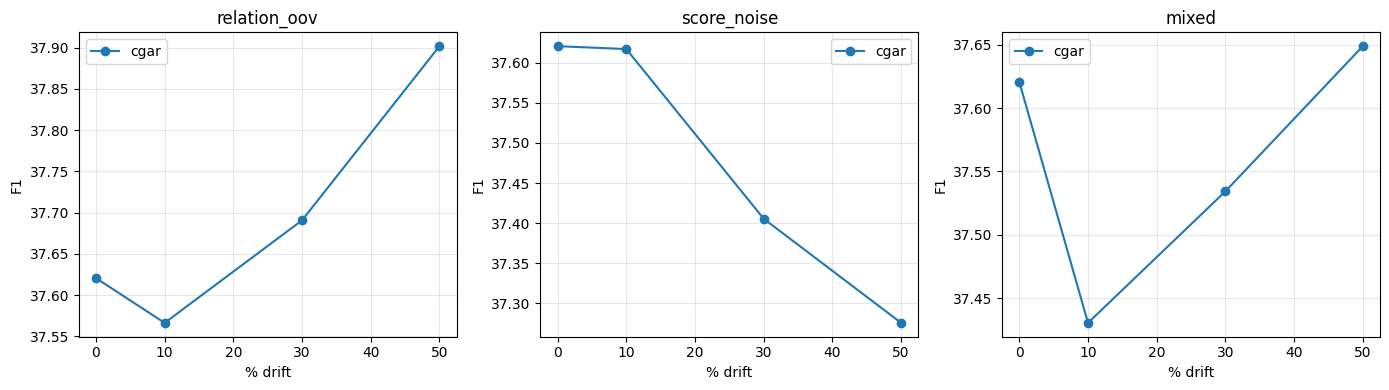

F1 drop @50% relation_oov: {'cgar': -0.28}
PASS  CGAR giảm -0.3 pp @50% relation_oov (< 10 pp: SBERT vẫn hiểu quan hệ lạ)


In [11]:
from kgqa_bench.data import drift_dataset
from kgqa_bench.methods import CGARMethod
from kgqa_bench.metrics import summarize_records
B10 = f'{RESULTS}/b10_drift'; os.makedirs(B10, exist_ok=True)
cm = CGARMethod(emb, device=DEVICE, max_paths=CGAR_BUDGET, learned_stop=('--cgar-learned-stop' in CGAR_FLAGS)).load(CGAR_CKPT)
methods_drift = [cm] + ([PRISMMethod(emb, cfg=CFG, device=DEVICE).load(PRISM_CKPT, vocab_path=PRISM_CKPT + '.vocab.json')] if RUN_PRISM else [])
sub = te.subset(600, seed=0)   # 600 câu đủ cho đường cong; bỏ .subset để chạy full
rows = []
for mode in ['relation_oov', 'score_noise', 'mixed']:
    for pct in [0.0, 0.1, 0.3, 0.5]:
        d = drift_dataset(sub, pct, mode, seed=0).annotate_hops()
        for m in methods_drift:
            s = summarize_records(m.run(d, verbose=False), n_bootstrap=200)
            rows.append(dict(mode=mode, pct=pct, method=m.name, f1=s['f1'], cov=s['cov'], cost=s['cost'], ece=s.get('ece')))
df = pd.DataFrame(rows); df.to_csv(f'{B10}/drift_curves.csv', index=False)
display(df.pivot_table(index=['mode','pct'], columns='method', values='f1').round(3))
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, mode in zip(axes, ['relation_oov','score_noise','mixed']):
    for m in [x.name for x in methods_drift]:
        q = df[(df['mode']==mode)&(df['method']==m)]; ax.plot(q['pct']*100, q['f1']*100, 'o-', label=m)
    ax.set_title(mode); ax.set_xlabel('% drift'); ax.set_ylabel('F1'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(f'{B10}/drift_curves.png', dpi=150); plt.show()
d0 = df[(df['mode']=='relation_oov')]
drop = {m: d0[(d0['method']==m)&(d0['pct']==0)]['f1'].item() - d0[(d0['method']==m)&(d0['pct']==0.5)]['f1'].item() for m in [x.name for x in methods_drift]}
print('F1 drop @50% relation_oov:', {k: round(v*100,2) for k,v in drop.items()})
if RUN_PRISM: gate(drop['prism'] <= drop['cgar'], 'PRISM giảm không nhiều hơn CGAR dưới relation_oov')
else: gate(drop['cgar'] < 0.10, f"CGAR giảm {drop['cgar']*100:.1f} pp @50% relation_oov (< 10 pp: SBERT vẫn hiểu quan hệ lạ)")

## 11 · Report và checklist claim
**Mục tiêu:** mọi con số trong paper truy ngược được về một `results.json` và một lệnh; mỗi claim chỉ được viết khi gate tương ứng đã qua.
**Tối thiểu cho Seminar 2:** bước 01, 02, 03, 06 (một seed), 08 (một reader). **EMNLP:** toàn bộ 00–11.

In [14]:
if 'B06' not in globals(): B06 = f'{RESULTS}/b06_main' + ('_v3' if CGAR_FLAGS else '')   # runtime mới, chưa chạy cell 06
!python -m kgqa_bench.cli report --results $B06 > /dev/null
print(open(f'{B06}/report.md').read()[:4000])

# Checklist claim <-> gate: đọc thẳng kết quả đã lưu trên Drive, không phụ thuộc cell nào đã chạy trong runtime này.
# [OK] đạt | [NO] không đạt -> Discussion/Limitations | [--] chưa có kết quả trên Drive hoặc nhánh không chạy
import glob, re
def _j(path):
    try:
        with open(path) as f: return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError): return None
def _dirs(prefix): return sorted(d for d in glob.glob(f'{RESULTS}/{prefix}_reader_*') if not re.search(r'_old\d*$', d))
def _sum(d): R = _j(f'{d}/results.json'); return R['summaries'].get('webqsp:test') if R else None
def _hal(d):
    H_ = _j(f'{d}/hallucination/hallucination.json')
    return list(H_['datasets'].values())[0] if H_ and H_.get('datasets') else None
def _pair(pa, pb):   # cùng reader, hai cấu hình
    out = []
    for d in _dirs(pa):
        e = f"{RESULTS}/{pb}_reader_{d.split('_reader_')[-1]}"
        if _hal(d) and os.path.isdir(e) and _hal(e): out.append((_hal(d)['summaries'], _hal(e)['summaries']))
    return out
def _notworse(c): return bool(c) and (c['bootstrap']['delta'] >= 0 or not c['significant_0.05'])
claims = []
if 'R06' not in globals(): R06 = load_results(B06)
s06 = R06['summaries']['webqsp:test']; c06 = R06['comparisons']['webqsp:test']

# --- retrieval (06, 06b, 06c, 07, 09, 10)
claims.append(('CGAR giảm cost ở cùng chất lượng retrieval: F1 không thua all và cost <= 80% (06)',
               _notworse(c06.get('cgar_vs_gnnrag_all:f1')) and s06['cgar']['cost'] <= 0.8 * s06['gnnrag_all']['cost']))
claims.append(('Confidence CGAR dùng được để abstain: AURC < gnnrag_top10 (07)', s06['cgar']['aurc'] < s06['gnnrag_top10']['aurc']))
RE_ = _j(f'{B06}/escalation/escalation_webqsp_test_cgar_to_gnnrag_all.json')
if RE_:
    _all = [r for r in RE_['rows'] if r['tau'] == '+inf'][0]
    _ok = any(r['tau'] != 'oracle' and r['cost'] <= 0.6 * _all['cost'] and r['f1'] >= _all['f1'] - 0.005 for r in RE_['rows'])
else: _ok = None
claims.append(('Escalation offline đạt F1 >= all - 0.5 pp ở <= 60% cost (06b)', _ok))
RA_ = _j(f'{B06}/analysis/analysis_webqsp_test.json')
_cs = (RA_ or {}).get('pairwise', {}).get('cgar:sbert_top5', {}).get('f1', {}).get('bootstrap', {})
claims.append(('CGAR > sbert_top5 về F1, CI không chứa 0 (06c)', (_cs.get('ci_low', -1) > 0) if RA_ else None))
claims.append(('Adaptive thật: controller tự dừng sớm ở >= 10% câu (06c)',
               (RA_.get('adaptivity', {}).get('categories', {}).get('controller_stopped_early', {}).get('frac', 0) >= 0.10) if RA_ else None))
claims.append(('Sweep cost tạo >= 3 mức cost (06; chỉ là đường Pareto, không chứng minh adaptive)',
               len({round(p['cost'], 1) for p in R06['train_logs'].get('cgar_cost_sweep', []) if p['dataset'] == 'webqsp:test'}) >= 3))
_s1, _rl = _j(f'{RESULTS}/b09_cgar_noRL/results.json'), _j(f'{RESULTS}/b09_cgar_withRL/results.json')
claims.append(('RL (Stage 2) không cần thiết (09)',
               (_rl['summaries']['webqsp:test']['cgar']['f1'] <= _s1['summaries']['webqsp:test']['cgar']['f1'] + 0.002) if _s1 and _rl else None))
_dc = f'{RESULTS}/b10_drift/drift_curves.csv'
if os.path.exists(_dc):
    _d = pd.read_csv(_dc); _d = _d[(_d['mode'] == 'relation_oov') & (_d['method'] == 'cgar')]
    _ok = (_d[_d['pct'] == 0]['f1'].item() - _d[_d['pct'] == 0.5]['f1'].item()) < 0.10
else: _ok = None
claims.append(('Bền với drift: F1 giảm < 10 pp ở 50% quan hệ lạ (10)', _ok))
claims.append(('CWQ chạy trên pool GNN (C2)', CWQ_TE.startswith('gnnrag:')))

# --- reader và hallucination (08, 08b/P9, 08c, 08d)
_chat = [d for d in _dirs('b08') if _sum(d) and 'no_retrieval' in _sum(d)]
claims.append((f'Retrieval giúp reader hơn không retrieval, mọi reader ({len(_chat)}) (08)',
               all(_sum(d)['gnnrag_all']['llm_hit'] > _sum(d)['no_retrieval']['llm_hit'] for d in _chat) if _chat else None))
_hal_all = {os.path.basename(d): _hal(d) for p in ('b08', 'b08g', 'b08v', 'b08c', 'b08f') for d in _dirs(p)}
_hal_all = {k: v for k, v in _hal_all.items() if v and 'cgar' in v['comparisons']}
def _hnotworse(v, m='cgar'):
    c = v['comparisons'].get(m, {}).get('hallucinated', {}).get('bootstrap', {})
    return bool(c) and (c['delta'] <= 0 or c['p_value'] >= 0.05)
claims.append((f'CGAR không tăng question-hallucination so với all, mọi reader/prompt ({len(_hal_all)} cấu hình) (P9)',
               all(_hnotworse(v) for v in _hal_all.values()) if _hal_all else None))
_hal_chat = {k: v for k, v in _hal_all.items() if k.startswith('b08_')}
def _hlower(v):
    c = v['comparisons'].get('cgar', {}).get('hallucinated', {}).get('bootstrap', {})
    return bool(c) and c['delta'] < 0 and c['p_value'] < 0.05
claims.append((f'CGAR giảm question-hallucination so với all có ý nghĩa, prompt chat ({len(_hal_chat)} reader) (P9)',
               all(_hlower(v) for v in _hal_chat.values()) if _hal_chat else None))
_gp = _pair('b08', 'b08g')
claims.append(('Prompt grounded giảm QHR của CGAR >= 2 pp mà grounded-correct giảm <= 3 pp (08, D1)',
               all(g['cgar']['question_hallucination_rate'] <= c['cgar']['question_hallucination_rate'] - 0.02 and
                   g['cgar']['grounded_correct_rate'] >= c['cgar']['grounded_correct_rate'] - 0.03 for c, g in _gp) if _gp else None))
_vp = _pair('b08', 'b08v')
claims.append(('Verify hậu kỳ giảm QHR của all và không giảm grounded-correct (08c)',
               all(v['gnnrag_all']['question_hallucination_rate'] < c['gnnrag_all']['question_hallucination_rate'] and
                   v['gnnrag_all']['grounded_correct_rate'] >= c['gnnrag_all']['grounded_correct_rate'] for c, v in _vp) if _vp else None))
_esc = _j(f'{RESULTS}/b06d_cgar_esc/results.json')
_se = _esc['summaries']['webqsp:test'] if _esc else None
claims.append(('cgar_esc: F1 retrieval không thua all có ý nghĩa (08c)',
               _notworse(_esc['comparisons']['webqsp:test'].get('cgar_esc_vs_gnnrag_all:f1')) if _esc else None))
claims.append(('cgar_esc: cost <= 80% all (08c)', (_se['cgar_esc']['cost'] <= 0.8 * _se['gnnrag_all']['cost']) if _esc else None))
for _p, _lab in (('b08c', 'reader zero-shot cand+verify'), ('b08f', 'reader LoRA cand+verify')):
    _ds = [d for d in _dirs(_p) if _j(f'{d}/results.json')]
    _cm = [_j(f'{d}/results.json')['comparisons']['webqsp:test'].get('cgar_esc_vs_gnnrag_all:llm_hit') for d in _ds]
    claims.append((f'cgar_esc không thua all về llm_hit cùng {_lab} ({len(_ds)} reader) (08c/08d)',
                   all(_notworse(c) for c in _cm) if _ds else None))

# --- PRISM (chỉ khi RUN_PRISM)
G = globals()
if RUN_PRISM:
    claims.append(('Distilled from LLM (05)', 'R05' in G and R05['train_logs']['prism@seed42']['teacher'] != 'oracle_heuristic' and f_llm >= f_orc - 0.01))
    claims.append(('PRISM LAS học được, không ở mức chance (04)', s06.get('prism', {}).get('las_hit1', 0) >= G.get('PRISM_CHANCE', 1/32) + 0.10))
else:
    claims += [('Distilled from LLM (05)', None), ('PRISM LAS học được, không ở mức chance (04)', None)]

_tag = {True: '[OK] ', False: '[NO] ', None: '[--] '}
_note = {True: '', False: '  -> hạ xuống Discussion/Limitations', None: '  (chưa có kết quả trên Drive hoặc nhánh không chạy)'}
for name, ok in claims:
    ok = None if ok is None else bool(ok)
    print(_tag[ok] + name + _note[ok])
print('\nMỗi claim [OK] viết kèm Δ, 95% CI, p lấy từ comparisons của bước tương ứng. KHÔNG dùng số placeholder trong PRISM_experiments.md / CGAR_abstract_v1.md.')


# KGQA bench report

Config: `{"cmd": "run", "train": "gnnrag:/content/drive/MyDrive/ThS/Research/colab/graph_rag/ckpt/gnn_features_train.pkl:webqsp:train", "eval": ["gnnrag:/content/drive/MyDrive/ThS/Research/colab/graph_rag/ckpt/gnn_features_webqsp_test.pkl:webqsp:test", "gnnrag:/content/drive/MyDrive/ThS/Research/colab/graph_rag/ckpt/gnn_features_cwq_test.pkl:cwq:test"], "methods": ["gnnrag_all", "gnnrag_top10", "gnnrag_top5", "sbert_top10", "sbert_top5", "graphrag_fi", "cgar"], "embedder": "sbert", "device": "cuda", "out": "/content/drive/MyDrive/ThS/Research/colab/graph_rag/results_gnn/b06_main", "max_items": null, "max_hops": 3, "score_sim": 0.0, "max_paths_per_pair": 3, "baseline_candidates": 20, "seeds": [42, 1337, 2024], "dev_split": 0.1, "dev_from_first_eval": false, "dev_max": 400, "reader": "none", "no_retrieval_baseline": false, "compare_ref": "gnnrag_all", "n_bootstrap": 10000, "sweep": true, "sweep_max": 600, "subset_seed": null, "quiet": true, "cgar_ckpt": null, "cgar_s